# Vertical Integrate Properties

To confirm diatom reproduction, integrate all the properties.

## Integration Preparation

### Mask and area

In [ ]:
# grid paths
import xarray as xr

# Save to
path_output='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_sensitivity/Data_Vertical_Integrate/'

# grids: tmesh, area and e3t
# paths

MASK_FILE = "/ocean/jqiu/Grid/mesh_mask202108.nc"
AREA_FILE = "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/SalishSea_1d_20230301_20230331_biol_T.nc"


ds_grid=xr.open_dataset(MASK_FILE)
tmask=ds_grid['tmask'] # String flag_meanings "land, water"; String flag_values "0, 1", (t, z, y, x)
e3t=ds_grid['e3t_1d'] # "Grid Spacing on T-grid in w Direction", (t, z)
depth=ds_grid['gdept_1d'] # "Depth of T-grid Points", String units "m", (t, z)

ds_area=xr.open_dataset(AREA_FILE)
area=ds_area['area'] # 


# Grid Regions
REGIONS = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365,  50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75,  125, 225, 280),
    "Pam Rocks":    (490, 510, 330, 350),
    "SandHeads":    (420, 440, 280, 300),
}

In [4]:
# grid size

print(ds_grid)

<xarray.Dataset> Size: 788MB
Dimensions:       (y: 898, x: 398, t: 1, z: 40)
Dimensions without coordinates: y, x, t, z
Data variables: (12/43)
    nav_lon       (y, x) float32 1MB ...
    nav_lat       (y, x) float32 1MB ...
    time_counter  (t) datetime64[ns] 8B ...
    tmask         (t, z, y, x) int8 14MB ...
    umask         (t, z, y, x) int8 14MB ...
    vmask         (t, z, y, x) int8 14MB ...
    ...            ...
    gdepv         (t, z, y, x) float32 57MB ...
    gdepw_0       (t, z, y, x) float32 57MB ...
    gdept_1d      (t, z) float64 320B ...
    gdepw_1d      (t, z) float64 320B ...
    e3t_1d        (t, z) float64 320B ...
    e3w_1d        (t, z) float64 320B ...
Attributes:
    file_name:    grid/mesh_mask202108.nc
    TimeStamp:    07/08/2021 17:25:49 -0700
    Conventions:  CF-1.6
    title:        SalishSeaCast NEMO bathymetry_202108 Bathymetry Mesh Mask
    institution:  Dept of Earth, Ocean & Atmospheric Sciences, University of ...
    source:       NEMO-3.6 S

In [5]:
# area and results size 

print(ds_area)

<xarray.Dataset> Size: 18GB
Dimensions:                       (y: 898, x: 398, nvertex: 4, deptht: 40,
                                   axis_nbounds: 2, time_counter: 31)
Coordinates:
    nav_lat                       (y, x) float32 1MB ...
    nav_lon                       (y, x) float32 1MB ...
  * deptht                        (deptht) float32 160B 0.5 1.5 ... 414.5 441.5
    time_centered                 (time_counter) datetime64[ns] 248B ...
  * time_counter                  (time_counter) datetime64[ns] 248B 2023-03-...
Dimensions without coordinates: y, x, nvertex, axis_nbounds
Data variables: (12/16)
    bounds_nav_lon                (y, x, nvertex) float32 6MB ...
    bounds_nav_lat                (y, x, nvertex) float32 6MB ...
    area                          (y, x) float32 1MB ...
    deptht_bounds                 (deptht, axis_nbounds) float32 320B ...
    time_centered_bounds          (time_counter, axis_nbounds) datetime64[ns] 496B ...
    time_counter_bounds         

In [7]:
# Total volume and volume weights

import numpy as np
import xarray as xr
from pathlib import Path

path_output_weights = '/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_sensitivity/Weights_Area/'

# Prepare grid


tmask_3d = ds_grid["tmask"].isel(t=0, drop=True)
e3t_1d = ds_grid["e3t_1d"].isel(t=0, drop=True)
area_2d = ds_area["area"].squeeze(drop=True)

# Cell volume (m3)
cell_volume = e3t_1d * area_2d * tmask_3d

# Rename vertical dimension
cell_volume = cell_volume.rename({"z": "deptht"})

# Assign actual depth coordinates
cell_volume = cell_volume.assign_coords(
    deptht=ds_area["deptht"]
)

# Consistent dimension order
cell_volume = cell_volume.transpose("deptht", "y", "x")

# Set land cells to NaN
cell_volume = cell_volume.where(cell_volume > 0)

# print(cell_volume)


# Calculate region weights


output_dir = Path(path_output_weights)
output_dir.mkdir(parents=True, exist_ok=True)

for region_name, (ymin, ymax, xmin, xmax) in REGIONS.items():

    # Regional cell volume
    volume_region = cell_volume.isel(
        y=slice(ymin, ymax),
        x=slice(xmin, xmax)
    )

    # Total volume (m3)
    total_volume = volume_region.sum(
        dim=("deptht", "y", "x")
    ).item()

    print(f"{region_name:15s}: {total_volume:.6e} m3")

    # Full-grid weight array
    # Outside region and land cells remain NaN
    weights = xr.full_like(
        cell_volume,
        np.nan,
        dtype=np.float64
    )

    # Volume-normalized weights
    weights.data[:, ymin:ymax, xmin:xmax] = (
        volume_region.data / total_volume
    )

    weights.name = "weights"

    weights.attrs = {
        "long_name": f"Volume weights for {region_name}",
        "description": "Normalized volume weights; NaN outside region and on land",
        "units": "1",
        "total_volume_m3": total_volume,
    }

    # Check weights
    weight_sum = weights.sum().item()

    print(f"   Sum of weights: {weight_sum:.8f}")

    assert np.isclose(weight_sum, 1.0), (
        f"Weight sum is not 1 for {region_name}"
    )

    # Save
    filename = (
        region_name.lower().replace(" ", "_")
        + "_weights.nc"
    )

    weights.to_dataset().to_netcdf(
        output_dir / filename
    )

    print(f"   Saved: {filename}")
    print()

Central SoG    : 1.516020e+11 m3
   Sum of weights: 1.00000000
   Saved: central_sog_weights.nc

Juan de Fuca   : 9.693112e+10 m3
   Sum of weights: 1.00000000
   Saved: juan_de_fuca_weights.nc

Haro Strait    : 3.272161e+10 m3
   Sum of weights: 1.00000000
   Saved: haro_strait_weights.nc

Northern SoG   : 8.262985e+10 m3
   Sum of weights: 1.00000000
   Saved: northern_sog_weights.nc

Puget Sound    : 3.464168e+10 m3
   Sum of weights: 1.00000000
   Saved: puget_sound_weights.nc

Pam Rocks      : 1.264526e+10 m3
   Sum of weights: 1.00000000
   Saved: pam_rocks_weights.nc

SandHeads      : 9.522862e+09 m3
   Sum of weights: 1.00000000
   Saved: sandheads_weights.nc



### Paths

In [20]:
# Example: "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/" + "SalishSea_1d_20230301_20230331_grid_T.nc"

EXPERIMENTS_head = {
    "HRDPS2.5": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS1": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps1/"
            "SalishSea_1d_20230301_20230328"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps1/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps1/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "CaSR": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_CaSR/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_CaSR/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS10": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps10/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps10/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps10/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS2.5+CaSR_wind": {
            "Mar": (
                "/ocean/jqiu/results/Sensivity/CaSR_wind_HRDPS_else/"
                "SalishSea_1d_20230301_20230331"
        ),
    },
    "CaSR+HRDPS2.5_wind": {
                "Mar": (
                    "/ocean/jqiu/results/Sensivity/HRDPS_wind_CaSR_else/"
                    "SalishSea_1d_20230301_20230331"
            ),
    },
}


EXPERIMENTS_tail = {
    'Physical': '_grid_T.nc',
    'Biological': '_biol_T.nc',
    'Velocity_u': '_grid_U.nc',
    'Velocity_v': '_grid_V.nc',
    'Chemical': '_chem_T.nc'
}

# List_month={'Mar','Jun','Sep','Dec'}
List_month={'Mar'}



## Biological Visualization

### Whole Area (All column)


Processing experiment: HRDPS2.5
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: HRDPS1
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: CaSR
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: HRDPS10
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: HRDPS2.5+CaSR_wind
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: CaSR+HRDPS2.5_wind
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates


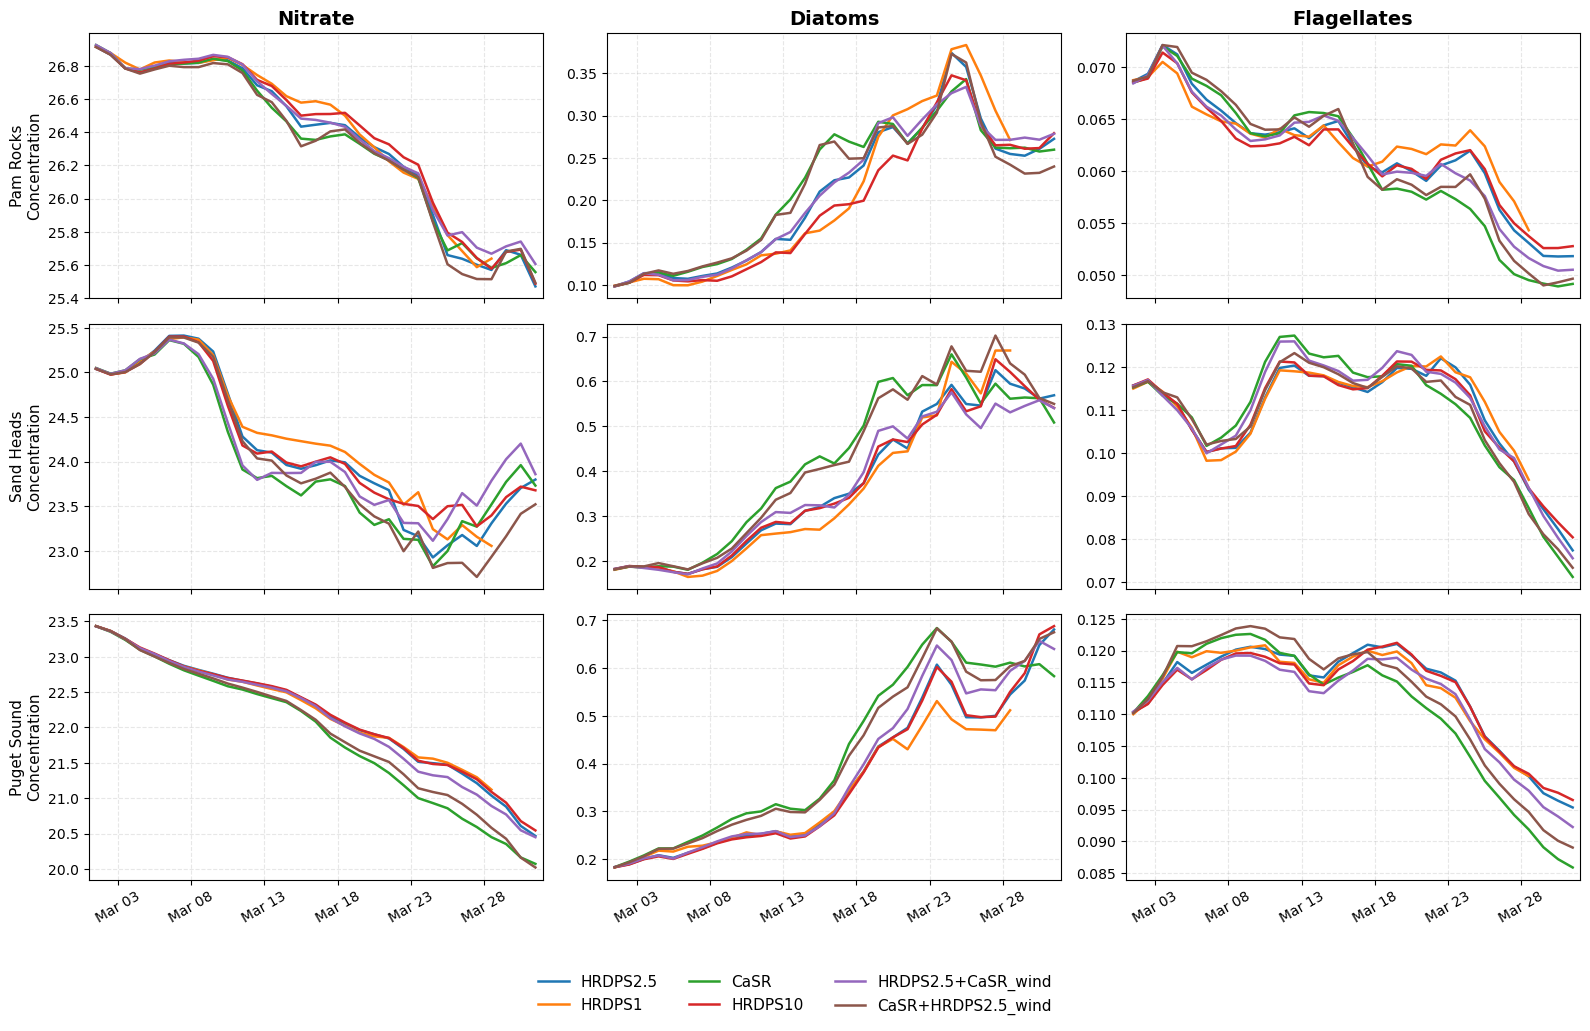

In [ ]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

#Settings


BIO_VARS = ("nitrate", "diatoms", "flagellates")

REGIONS_TO_PLOT = {
    "Pam Rocks": "pam_rocks",
    "Sand Heads": "sandheads",
    "Puget Sound": "puget_sound",
}

MONTH = "Mar"

path_weights = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_sensitivity/Weights_Area/"
)



# Experiment colors
EXPERIMENT_COLORS = {
    "HRDPS2.5": "tab:blue",
    "HRDPS1": "tab:orange",
    "CaSR": "tab:green",
    "HRDPS10": "tab:red",
    "HRDPS2.5+CaSR_wind": "tab:purple",
    "CaSR+HRDPS2.5_wind": "tab:brown",
}



# Load regional weights


region_weights = {}

for region_name, region_file in REGIONS_TO_PLOT.items():

    weight_file = path_weights / f"{region_file}_weights.nc"

    with xr.open_dataset(weight_file) as ds_w:
        region_weights[region_name] = ds_w["weights"].load()

    # print(
    #     f"{region_name:15s}: "
    #     f"weights sum = "
    #     f"{region_weights[region_name].sum().item():.6f}"
    # )



# Calculate volume-weighted regional means


# Structure:
# results[region][variable][experiment] = DataArray(time_counter)

results = {
    region: {var: {} for var in BIO_VARS}
    for region in REGIONS_TO_PLOT
}

spatial_dims = ("deptht", "y", "x")

for exp_name, exp_paths in EXPERIMENTS_head.items():

    if MONTH not in exp_paths:
        continue

    file_path = (
        exp_paths[MONTH]
        + EXPERIMENTS_tail["Biological"]
    )

    if not Path(file_path).exists():
        print(f"File not found: {file_path}")
        continue

    print(f"\nProcessing experiment: {exp_name}")

    with xr.open_dataset(file_path, chunks={"time_counter": 1}) as ds:

        for var_name in BIO_VARS:

            if var_name not in ds:
                print(f"  Variable not found: {var_name}")
                continue

            var = ds[var_name]

            for region_name, weights in region_weights.items():

                # Volume-weighted mean
                # Renormalize for any missing values
                numerator = (var * weights).sum(
                    dim=spatial_dims
                )

                denominator = weights.where(
                    var.notnull()
                ).sum(dim=spatial_dims)

                regional_mean = numerator / denominator

                # Load only the reduced time series
                results[region_name][var_name][exp_name] = (
                    regional_mean.load()
                )

            print(f"  Finished: {var_name}")


# Visualize


fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(16, 11),
    sharex=True
)

regions = list(REGIONS_TO_PLOT.keys())

var_labels = {
    "nitrate": "Nitrate",
    "diatoms": "Diatoms",
    "flagellates": "Flagellates",
}

for i, region_name in enumerate(regions):

    for j, var_name in enumerate(BIO_VARS):

        ax = axes[i, j]

        for exp_name, ts in results[region_name][var_name].items():

            ax.plot(
                ts["time_counter"].values,
                ts.values,
                label=exp_name,
                color=EXPERIMENT_COLORS.get(exp_name),
                linewidth=1.8,
            )

        if i == 0:
            ax.set_title(
                var_labels[var_name],
                fontsize=14,
                fontweight="bold"
            )

        if j == 0:
            ax.set_ylabel(
                f"{region_name}\nConcentration",
                fontsize=11
            )

        ax.grid(alpha=0.3, linestyle="--")

        ax.xaxis.set_major_locator(
            mdates.DayLocator(interval=5)
        )
        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%b %d")
        )

        ax.tick_params(axis="x", rotation=30)

        ax.set_xlim(
            np.datetime64("2023-03-01"),
            np.datetime64("2023-04-01")
        )

# Collect legend entries
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    fontsize=11
)

# fig.suptitle(
#     "Regional Volume-Weighted Biological Concentrations\n"
#     "March 2023",
#     fontsize=17,
#     fontweight="bold",
#     y=0.99
# )

plt.tight_layout(rect=[0, 0.09, 1, 0.95])

plt.show()



### Top 20 meters

In [12]:
# recalculate volume
# Total volume of top 20 layers for each region

import xarray as xr


# grid


tmask_3d = ds_grid["tmask"].isel(t=0, z=slice(0, 20), drop=True)
e3t_1d = ds_grid["e3t_1d"].isel(t=0, z=slice(0, 20), drop=True)
area_2d = ds_area["area"].squeeze(drop=True)

# Cell volume (m3)
cell_volume = e3t_1d * area_2d * tmask_3d

# Set land cells to NaN
cell_volume = cell_volume.where(tmask_3d == 1)


# Calculate total volume for each region


print("Total volume of top 20 layers")
print("-" * 55)

for region_name, (ymin, ymax, xmin, xmax) in REGIONS.items():

    # Regional cell volume (top 20 layers)
    volume_region = cell_volume.isel(
        y=slice(ymin, ymax),
        x=slice(xmin, xmax)
    )

    # Total volume (m3)
    total_volume = volume_region.sum(
        dim=("z", "y", "x")
    ).item()

    print(f"{region_name:15s}: {total_volume:.6e} m³")

Total volume of top 20 layers
-------------------------------------------------------
Central SoG    : 1.207505e+10 m³
Juan de Fuca   : 1.324345e+10 m³
Haro Strait    : 6.476011e+09 m³
Northern SoG   : 9.260634e+09 m³
Puget Sound    : 5.428035e+09 m³
Pam Rocks      : 1.466223e+09 m³
SandHeads      : 1.591821e+09 m³


Pam Rocks      : Top 20 layers weights sum = 1.000000
Sand Heads     : Top 20 layers weights sum = 1.000000
Puget Sound    : Top 20 layers weights sum = 1.000000

Processing experiment: HRDPS2.5
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: HRDPS1
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: CaSR
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: HRDPS10
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: HRDPS2.5+CaSR_wind
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: CaSR+HRDPS2.5_wind
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates


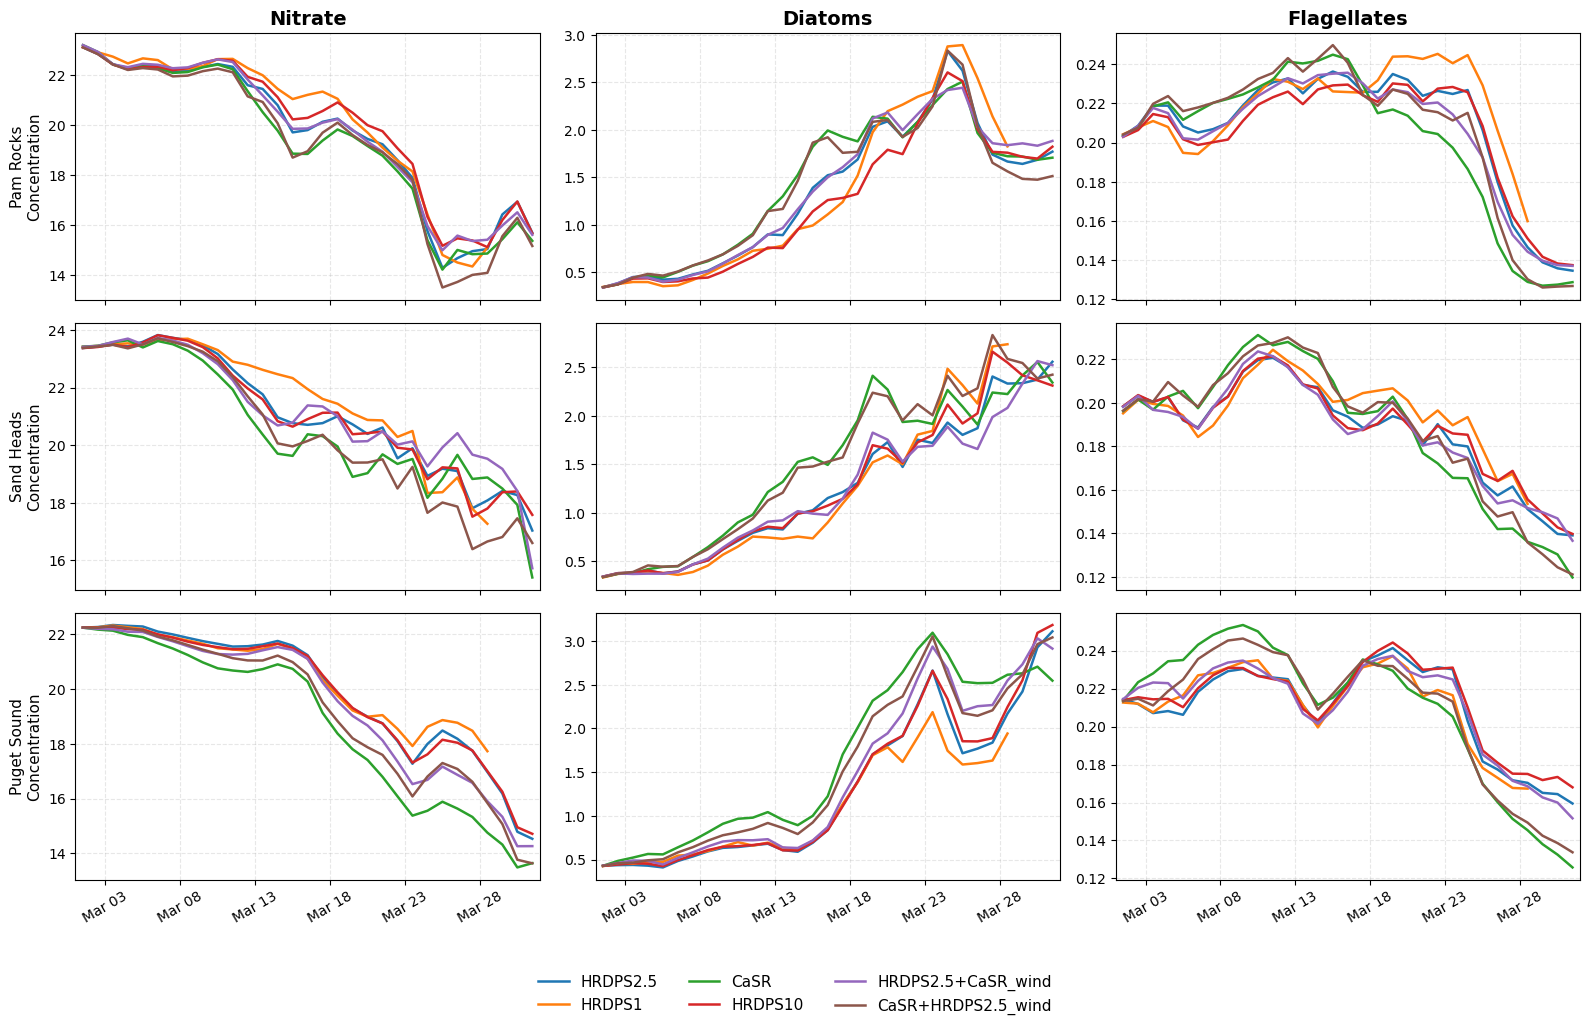

In [ ]:
# visualize

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# ============================================================
# Settings
# ============================================================

BIO_VARS = ("nitrate", "diatoms", "flagellates")

REGIONS_TO_PLOT = {
    "Pam Rocks": "pam_rocks",
    "Sand Heads": "sandheads",
    "Puget Sound": "puget_sound",
}

MONTH = "Mar"
N_LEVELS = 20  # Top 20 vertical layers

path_weights = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_sensitivity/Weights_Area/"
)

# Experiment colors
EXPERIMENT_COLORS = {
    "HRDPS2.5": "tab:blue",
    "HRDPS1": "tab:orange",
    "CaSR": "tab:green",
    "HRDPS10": "tab:red",
    "HRDPS2.5+CaSR_wind": "tab:purple",
    "CaSR+HRDPS2.5_wind": "tab:brown",
}


# ============================================================
# 1. Load regional weights (Top 20 layers)
# ============================================================

region_weights = {}

for region_name, region_file in REGIONS_TO_PLOT.items():

    weight_file = path_weights / f"{region_file}_weights.nc"

    with xr.open_dataset(weight_file) as ds_w:

        # Select top 20 layers
        weights = ds_w["weights"].isel(
            deptht=slice(0, N_LEVELS)
        ).load()

    # Renormalize weights for top 20 layers
    weights = weights / weights.sum(
        dim=("deptht", "y", "x")
    )

    region_weights[region_name] = weights

    print(
        f"{region_name:15s}: "
        f"Top {N_LEVELS} layers weights sum = "
        f"{weights.sum().item():.6f}"
    )



# Calculate regional means


# Structure:
# results[region][variable][experiment] = DataArray(time_counter)

results = {
    region: {var: {} for var in BIO_VARS}
    for region in REGIONS_TO_PLOT
}

spatial_dims = ("deptht", "y", "x")

for exp_name, exp_paths in EXPERIMENTS_head.items():

    if MONTH not in exp_paths:
        continue

    file_path = (
        exp_paths[MONTH]
        + EXPERIMENTS_tail["Biological"]
    )

    if not Path(file_path).exists():
        print(f"File not found: {file_path}")
        continue

    print(f"\nProcessing experiment: {exp_name}")

    with xr.open_dataset(
        file_path,
        chunks={"time_counter": 1}
    ) as ds:

        for var_name in BIO_VARS:

            if var_name not in ds:
                print(f"  Variable not found: {var_name}")
                continue

            # Select top 20 layers
            var = ds[var_name].isel(
                deptht=slice(0, N_LEVELS)
            )

            for region_name, weights in region_weights.items():

                # Volume-weighted mean
                # Renormalize for any missing values

                numerator = (var * weights).sum(
                    dim=spatial_dims
                )

                denominator = weights.where(
                    var.notnull()
                ).sum(dim=spatial_dims)

                regional_mean = numerator / denominator

                # Load only the reduced time series
                results[region_name][var_name][exp_name] = (
                    regional_mean.load()
                )

            print(f"  Finished: {var_name}")



# Visualize


fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(16, 11),
    sharex=True
)

regions = list(REGIONS_TO_PLOT.keys())

var_labels = {
    "nitrate": "Nitrate",
    "diatoms": "Diatoms",
    "flagellates": "Flagellates",
}

for i, region_name in enumerate(regions):

    for j, var_name in enumerate(BIO_VARS):

        ax = axes[i, j]

        for exp_name, ts in results[region_name][var_name].items():

            ax.plot(
                ts["time_counter"].values,
                ts.values,
                label=exp_name,
                color=EXPERIMENT_COLORS.get(exp_name),
                linewidth=1.8,
            )

        if i == 0:
            ax.set_title(
                var_labels[var_name],
                fontsize=14,
                fontweight="bold"
            )

        if j == 0:
            ax.set_ylabel(
                f"{region_name}\nConcentration",
                fontsize=11
            )

        ax.grid(alpha=0.3, linestyle="--")

        ax.xaxis.set_major_locator(
            mdates.DayLocator(interval=5)
        )

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%b %d")
        )

        ax.tick_params(axis="x", rotation=30)

        ax.set_xlim(
            np.datetime64("2023-03-01"),
            np.datetime64("2023-04-01")
        )



# Legend and layout


handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    fontsize=11
)

plt.tight_layout(rect=[0, 0.09, 1, 0.95])

plt.show()

## Wind Stress


Reading: /ocean/jqiu/results/Flux/flux_00mar23_CaSR/SalishSea_1d_20230301_20230331_sbfx_T.nc
  Finished: Pam Rocks
  Finished: Sand Heads
  Finished: Puget Sound

Reading: /ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/SalishSea_1d_20230301_20230331_sbfx_T.nc
  Finished: Pam Rocks
  Finished: Sand Heads
  Finished: Puget Sound

Reading: /ocean/jqiu/results/Sensivity/CaSR_wind_HRDPS_else/SalishSea_1d_20230301_20230331_sbfx_T.nc
  Finished: Pam Rocks
  Finished: Sand Heads
  Finished: Puget Sound

Reading: /ocean/jqiu/results/Sensivity/HRDPS_wind_CaSR_else/SalishSea_1d_20230301_20230331_sbfx_T.nc
  Finished: Pam Rocks
  Finished: Sand Heads
  Finished: Puget Sound

Reading: /ocean/jqiu/results/Flux/flux_00mar23_hrdps1/SalishSea_1d_20230301_20230328_sbfx_T.nc
  Finished: Pam Rocks
  Finished: Sand Heads
  Finished: Puget Sound

Reading: /ocean/jqiu/results/Flux/flux_00mar23_hrdps10/SalishSea_1d_20230301_20230331_sbfx_T.nc
  Finished: Pam Rocks
  Finished: Sand Heads
  Finished: Puget Sou

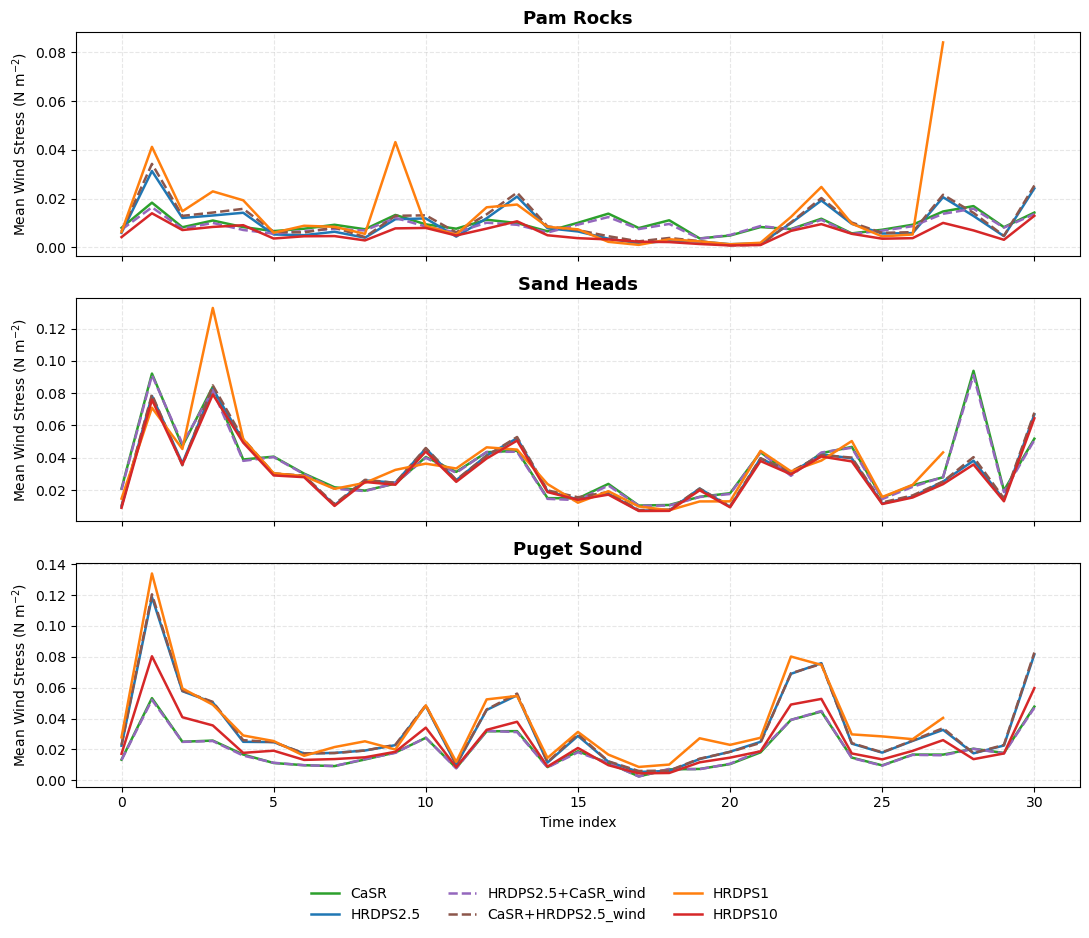

In [ ]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path


MONTH = "Mar"  # "Mar", "Jun", "Sep", "Dec"

MODELS = [
    "CaSR",
    "HRDPS2.5",
    "HRDPS2.5+CaSR_wind",
    "CaSR+HRDPS2.5_wind",
    "HRDPS1",
    "HRDPS10",
]

VARIABLE = "wind stress"
FILE_SUFFIX = "_sbfx_T.nc"

REGIONS_TO_PLOT = {
    "Pam Rocks": (490, 510, 330, 350),
    "Sand Heads": (420, 440, 280, 300),
    "Puget Sound": (75, 125, 225, 280),
}

EXPERIMENT_COLORS = {
    "HRDPS2.5": "tab:blue",
    "HRDPS1": "tab:orange",
    "CaSR": "tab:green",
    "HRDPS10": "tab:red",
    "HRDPS2.5+CaSR_wind": "tab:purple",
    "CaSR+HRDPS2.5_wind": "tab:brown",
}

LINESTYLES = {
    "HRDPS2.5": "-",
    "HRDPS1": "-",
    "CaSR": "-",
    "HRDPS10": "-",
    "HRDPS2.5+CaSR_wind": "--",
    "CaSR+HRDPS2.5_wind": "--",
}


# area weights

# Horizontal grid cell area (y, x)
area_2d = ds_area["area"].squeeze(drop=True)

# Surface ocean mask (y, x)
surface_mask = ds_grid["tmask"].isel(
    t=0, z=0, drop=True
)

# Land cells excluded
area_weights = area_2d.where(surface_mask == 1)



# read and calculate

# results[region][model] = 1D time series

results = {
    region: {}
    for region in REGIONS_TO_PLOT
}

for model in MODELS:

    if MONTH not in EXPERIMENTS_head.get(model, {}):
        print(f"WARNING: {MONTH} not available for {model}")
        continue

    file_path = Path(
        EXPERIMENTS_head[model][MONTH] + FILE_SUFFIX
    )

    print(f"\nReading: {file_path}")

    if not file_path.exists():
        print(f"WARNING: file not found: {file_path}")
        continue

    with xr.open_dataset(file_path) as ds:

        if VARIABLE not in ds:
            print(f"WARNING: {VARIABLE} not found")
            continue

        for region_name, (j0, j1, i0, i1) in REGIONS_TO_PLOT.items():

            # Select regional wind stress
            data = ds[VARIABLE].isel(
                y=slice(j0, j1),
                x=slice(i0, i1)
            )

            # Select regional area weights
            weights = area_weights.isel(
                y=slice(j0, j1),
                x=slice(i0, i1)
            )

            # Remove invalid values
            data = data.where(np.isfinite(data))

            # Area-weighted regional mean
            numerator = (data * weights).sum(
                dim=("y", "x"),
                skipna=True
            )

            denominator = weights.where(
                data.notnull()
            ).sum(
                dim=("y", "x"),
                skipna=True
            )

            mean_data = numerator / denominator

            results[region_name][model] = mean_data.values

            print(f"  Finished: {region_name}")


# visualize

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(11, 10),
    sharex=True
)

for i, (region_name, region_results) in enumerate(results.items()):

    ax = axes[i]

    for model in MODELS:

        if model not in region_results:
            continue

        mean_data = region_results[model]
        time_idx = np.arange(len(mean_data))

        ax.plot(
            time_idx,
            mean_data,
            label=model,
            color=EXPERIMENT_COLORS[model],
            linestyle=LINESTYLES[model],
            linewidth=1.8
        )

    ax.set_title(
        region_name,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_ylabel("Mean Wind Stress (N m$^{-2}$)")

    ax.grid(alpha=0.3, linestyle="--")

# Only bottom panel has x-axis label
axes[-1].set_xlabel("Time index")



handles, labels = [], []
for ax in axes:
    h, l = ax.get_legend_handles_labels()
    for handle, label in zip(h, l):
        if label not in labels:
            handles.append(handle)
            labels.append(label)

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    fontsize=10
)




plt.tight_layout(rect=[0, 0.10, 1, 0.95])

plt.show()

## PAR (light available)

### Top 20 layers

Pam Rocks      : Top 20 layers weights sum = 1.000000
Sand Heads     : Top 20 layers weights sum = 1.000000
Puget Sound    : Top 20 layers weights sum = 1.000000

Processing experiment: HRDPS2.5
  Finished: PAR

Processing experiment: HRDPS1
  Finished: PAR

Processing experiment: CaSR
  Finished: PAR

Processing experiment: HRDPS10
  Finished: PAR

Processing experiment: HRDPS2.5+CaSR_wind
  Finished: PAR

Processing experiment: CaSR+HRDPS2.5_wind
  Finished: PAR


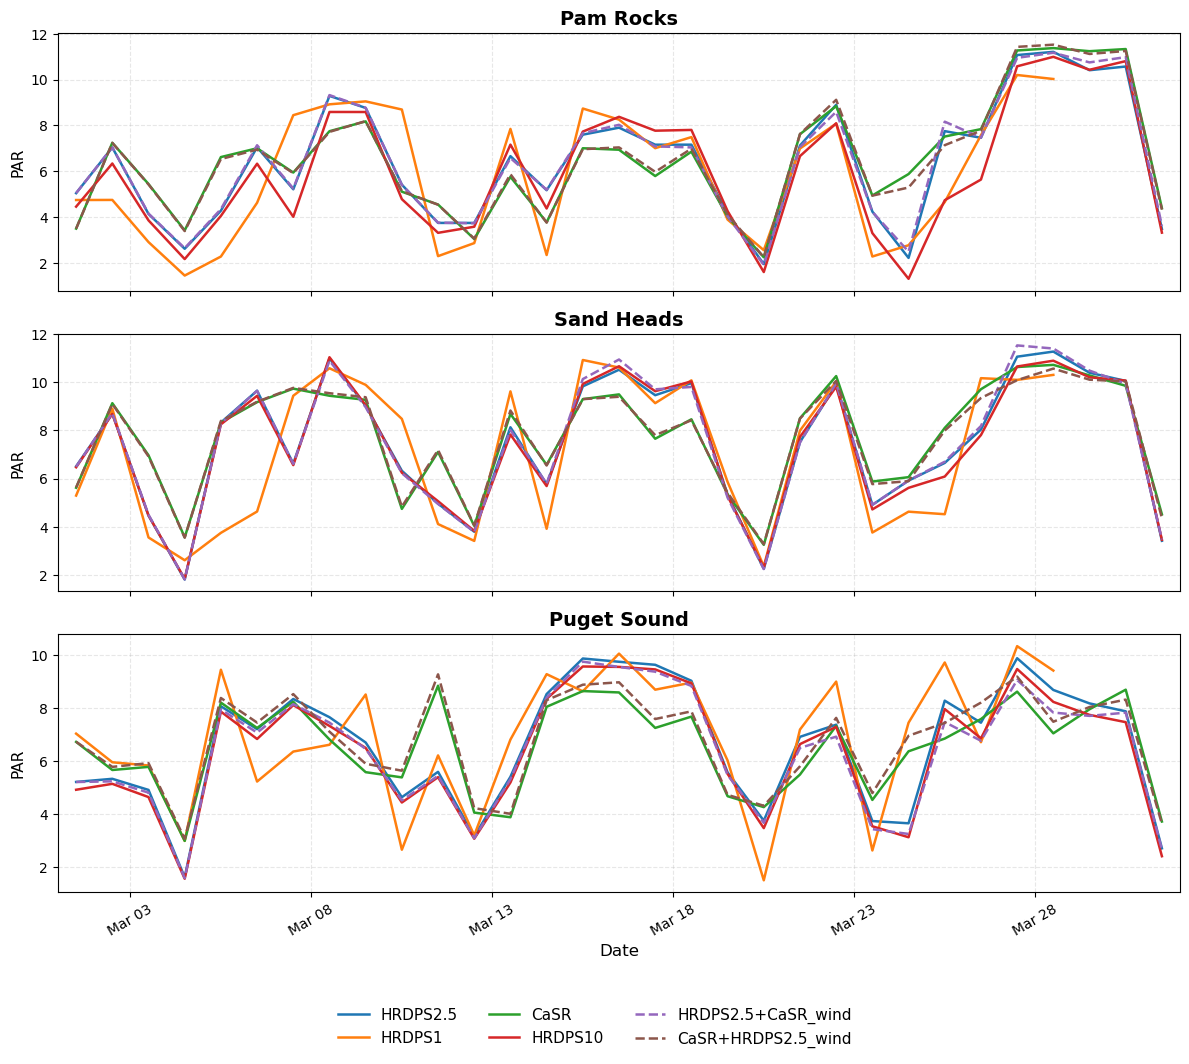

In [22]:
# visualize PAR (Chemical)

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# ============================================================
# Settings
# ============================================================

VAR_NAME = "PAR"

REGIONS_TO_PLOT = {
    "Pam Rocks": "pam_rocks",
    "Sand Heads": "sandheads",
    "Puget Sound": "puget_sound",
}

MONTH = "Mar"
N_LEVELS = 20  # Top 20 vertical layers

path_weights = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_sensitivity/Weights_Area/"
)

# Experiment colors
EXPERIMENT_COLORS = {
    "HRDPS2.5": "tab:blue",
    "HRDPS1": "tab:orange",
    "CaSR": "tab:green",
    "HRDPS10": "tab:red",
    "HRDPS2.5+CaSR_wind": "tab:purple",
    "CaSR+HRDPS2.5_wind": "tab:brown",
}


LINESTYLES = {
    "HRDPS2.5": "-",
    "HRDPS1": "-",
    "CaSR": "-",
    "HRDPS10": "-",
    "HRDPS2.5+CaSR_wind": "--",
    "CaSR+HRDPS2.5_wind": "--",
}

# Load Weights

region_weights = {}

for region_name, region_file in REGIONS_TO_PLOT.items():

    weight_file = path_weights / f"{region_file}_weights.nc"

    with xr.open_dataset(weight_file) as ds_w:

        weights = ds_w["weights"].isel(
            deptht=slice(0, N_LEVELS)
        ).load()

    # Renormalize weights for top 20 layers
    weights = weights / weights.sum(
        dim=("deptht", "y", "x")
    )

    region_weights[region_name] = weights

    print(
        f"{region_name:15s}: "
        f"Top {N_LEVELS} layers weights sum = "
        f"{weights.sum().item():.6f}"
    )


# Calculate means


# Structure:
# results[region][experiment] = DataArray(time_counter)

results = {
    region: {}
    for region in REGIONS_TO_PLOT
}

spatial_dims = ("deptht", "y", "x")

for exp_name, exp_paths in EXPERIMENTS_head.items():

    if MONTH not in exp_paths:
        continue

    file_path = (
        exp_paths[MONTH]
        + EXPERIMENTS_tail["Chemical"]
    )

    if not Path(file_path).exists():
        print(f"File not found: {file_path}")
        continue

    print(f"\nProcessing experiment: {exp_name}")

    with xr.open_dataset(
        file_path,
        chunks={"time_counter": 1}
    ) as ds:

        if VAR_NAME not in ds:
            print(f"  Variable not found: {VAR_NAME}")
            continue

        # Select top 20 layers
        var = ds[VAR_NAME].isel(
            deptht=slice(0, N_LEVELS)
        )

        for region_name, weights in region_weights.items():

            # Volume-weighted mean
            # Renormalize for any missing values

            numerator = (var * weights).sum(
                dim=spatial_dims
            )

            denominator = weights.where(
                var.notnull()
            ).sum(dim=spatial_dims)

            regional_mean = numerator / denominator

            # Load only the reduced time series
            results[region_name][exp_name] = (
                regional_mean.load()
            )

        print(f"  Finished: {VAR_NAME}")


# Visualize PAR 

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 11),
    sharex=True
)

regions = list(REGIONS_TO_PLOT.keys())

for i, region_name in enumerate(regions):

    ax = axes[i]

    for exp_name, ts in results[region_name].items():

        ax.plot(
            ts["time_counter"].values,
            ts.values,
            label=exp_name,
            color=EXPERIMENT_COLORS.get(exp_name),
            linestyle=LINESTYLES.get(exp_name),
            linewidth=1.8,
        )

    ax.set_title(
        region_name,
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel(
        "PAR",
        fontsize=11
    )

    ax.grid(alpha=0.3, linestyle="--")

    ax.xaxis.set_major_locator(
        mdates.DayLocator(interval=5)
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%b %d")
    )

    ax.tick_params(axis="x", rotation=30)

    ax.set_xlim(
        np.datetime64("2023-03-01"),
        np.datetime64("2023-04-01")
    )

axes[-1].set_xlabel("Date", fontsize=12)


# layout


handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    fontsize=11
)

plt.tight_layout(rect=[0, 0.09, 1, 0.98])

plt.show()

### Top 10 Layers

Pam Rocks      : Top 10 layers weights sum = 1.000000
Sand Heads     : Top 10 layers weights sum = 1.000000
Puget Sound    : Top 10 layers weights sum = 1.000000

Processing experiment: HRDPS2.5
  Finished: PAR

Processing experiment: HRDPS1
  Finished: PAR

Processing experiment: CaSR
  Finished: PAR

Processing experiment: HRDPS10
  Finished: PAR

Processing experiment: HRDPS2.5+CaSR_wind
  Finished: PAR

Processing experiment: CaSR+HRDPS2.5_wind
  Finished: PAR


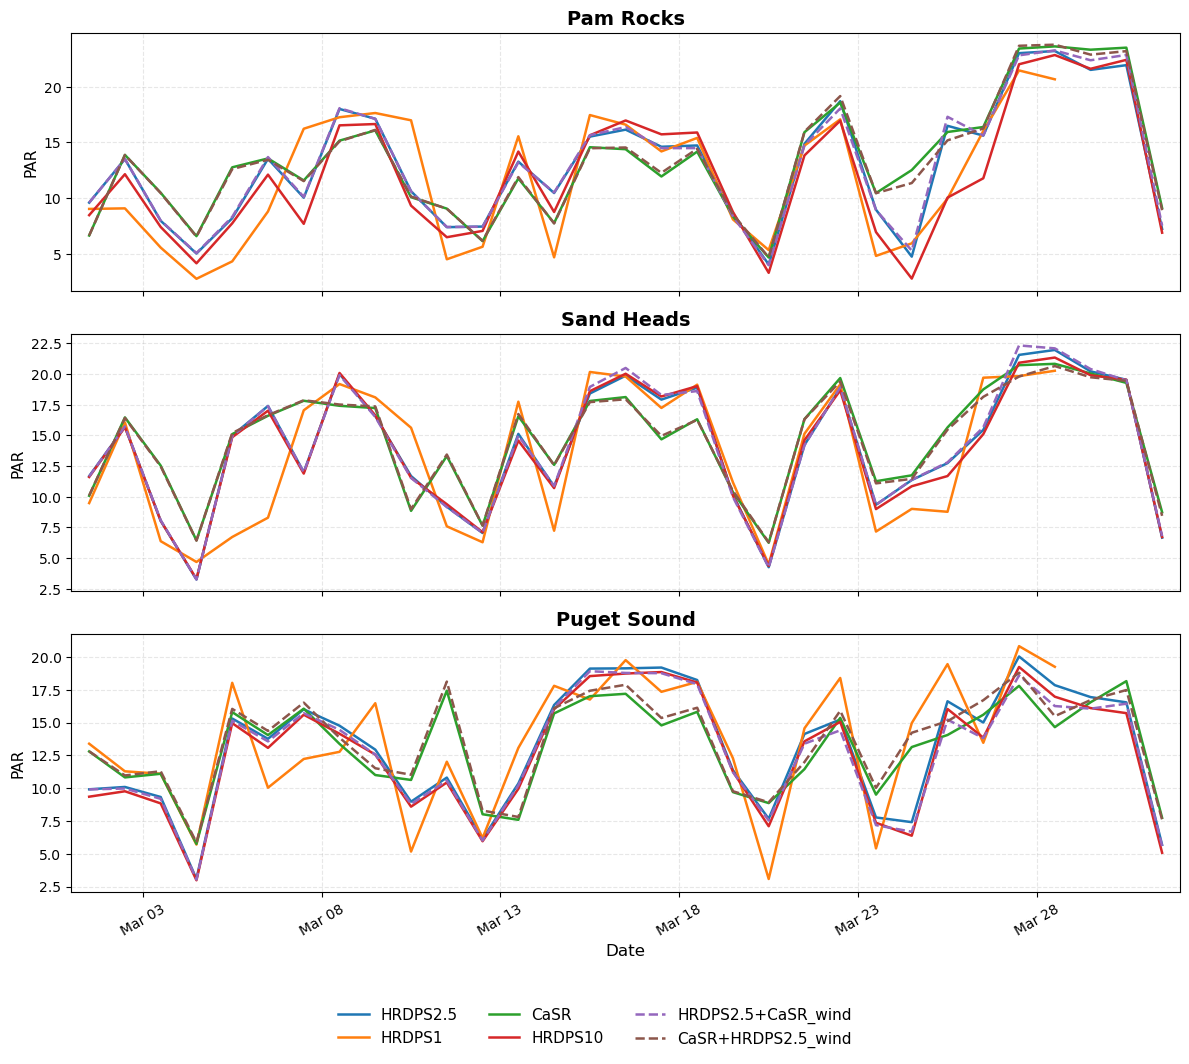

In [23]:
# visualize PAR (Chemical)

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# ============================================================
# Settings
# ============================================================

VAR_NAME = "PAR"

REGIONS_TO_PLOT = {
    "Pam Rocks": "pam_rocks",
    "Sand Heads": "sandheads",
    "Puget Sound": "puget_sound",
}

MONTH = "Mar"
N_LEVELS = 10  # Top 10 vertical layers

path_weights = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_sensitivity/Weights_Area/"
)

# Experiment colors
EXPERIMENT_COLORS = {
    "HRDPS2.5": "tab:blue",
    "HRDPS1": "tab:orange",
    "CaSR": "tab:green",
    "HRDPS10": "tab:red",
    "HRDPS2.5+CaSR_wind": "tab:purple",
    "CaSR+HRDPS2.5_wind": "tab:brown",
}


LINESTYLES = {
    "HRDPS2.5": "-",
    "HRDPS1": "-",
    "CaSR": "-",
    "HRDPS10": "-",
    "HRDPS2.5+CaSR_wind": "--",
    "CaSR+HRDPS2.5_wind": "--",
}

# Load Weights

region_weights = {}

for region_name, region_file in REGIONS_TO_PLOT.items():

    weight_file = path_weights / f"{region_file}_weights.nc"

    with xr.open_dataset(weight_file) as ds_w:

        weights = ds_w["weights"].isel(
            deptht=slice(0, N_LEVELS)
        ).load()

    # Renormalize weights for top 20 layers
    weights = weights / weights.sum(
        dim=("deptht", "y", "x")
    )

    region_weights[region_name] = weights

    print(
        f"{region_name:15s}: "
        f"Top {N_LEVELS} layers weights sum = "
        f"{weights.sum().item():.6f}"
    )


# Calculate means


# Structure:
# results[region][experiment] = DataArray(time_counter)

results = {
    region: {}
    for region in REGIONS_TO_PLOT
}

spatial_dims = ("deptht", "y", "x")

for exp_name, exp_paths in EXPERIMENTS_head.items():

    if MONTH not in exp_paths:
        continue

    file_path = (
        exp_paths[MONTH]
        + EXPERIMENTS_tail["Chemical"]
    )

    if not Path(file_path).exists():
        print(f"File not found: {file_path}")
        continue

    print(f"\nProcessing experiment: {exp_name}")

    with xr.open_dataset(
        file_path,
        chunks={"time_counter": 1}
    ) as ds:

        if VAR_NAME not in ds:
            print(f"  Variable not found: {VAR_NAME}")
            continue

        # Select top 20 layers
        var = ds[VAR_NAME].isel(
            deptht=slice(0, N_LEVELS)
        )

        for region_name, weights in region_weights.items():

            # Volume-weighted mean
            # Renormalize for any missing values

            numerator = (var * weights).sum(
                dim=spatial_dims
            )

            denominator = weights.where(
                var.notnull()
            ).sum(dim=spatial_dims)

            regional_mean = numerator / denominator

            # Load only the reduced time series
            results[region_name][exp_name] = (
                regional_mean.load()
            )

        print(f"  Finished: {VAR_NAME}")


# Visualize PAR 

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 11),
    sharex=True
)

regions = list(REGIONS_TO_PLOT.keys())

for i, region_name in enumerate(regions):

    ax = axes[i]

    for exp_name, ts in results[region_name].items():

        ax.plot(
            ts["time_counter"].values,
            ts.values,
            label=exp_name,
            color=EXPERIMENT_COLORS.get(exp_name),
            linestyle=LINESTYLES.get(exp_name),
            linewidth=1.8,
        )

    ax.set_title(
        region_name,
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel(
        "PAR",
        fontsize=11
    )

    ax.grid(alpha=0.3, linestyle="--")

    ax.xaxis.set_major_locator(
        mdates.DayLocator(interval=5)
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%b %d")
    )

    ax.tick_params(axis="x", rotation=30)

    ax.set_xlim(
        np.datetime64("2023-03-01"),
        np.datetime64("2023-04-01")
    )

axes[-1].set_xlabel("Date", fontsize=12)


# layout


handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    fontsize=11
)

plt.tight_layout(rect=[0, 0.09, 1, 0.98])

plt.show()

## Temperature (Probably nothing fun)

Pam Rocks      : Top 20 layers weights sum = 1.000000
Sand Heads     : Top 20 layers weights sum = 1.000000
Puget Sound    : Top 20 layers weights sum = 1.000000

Processing experiment: HRDPS2.5
  Finished: votemper

Processing experiment: HRDPS1
  Finished: votemper

Processing experiment: CaSR
  Finished: votemper

Processing experiment: HRDPS10
  Finished: votemper

Processing experiment: HRDPS2.5+CaSR_wind
  Finished: votemper

Processing experiment: CaSR+HRDPS2.5_wind
  Finished: votemper


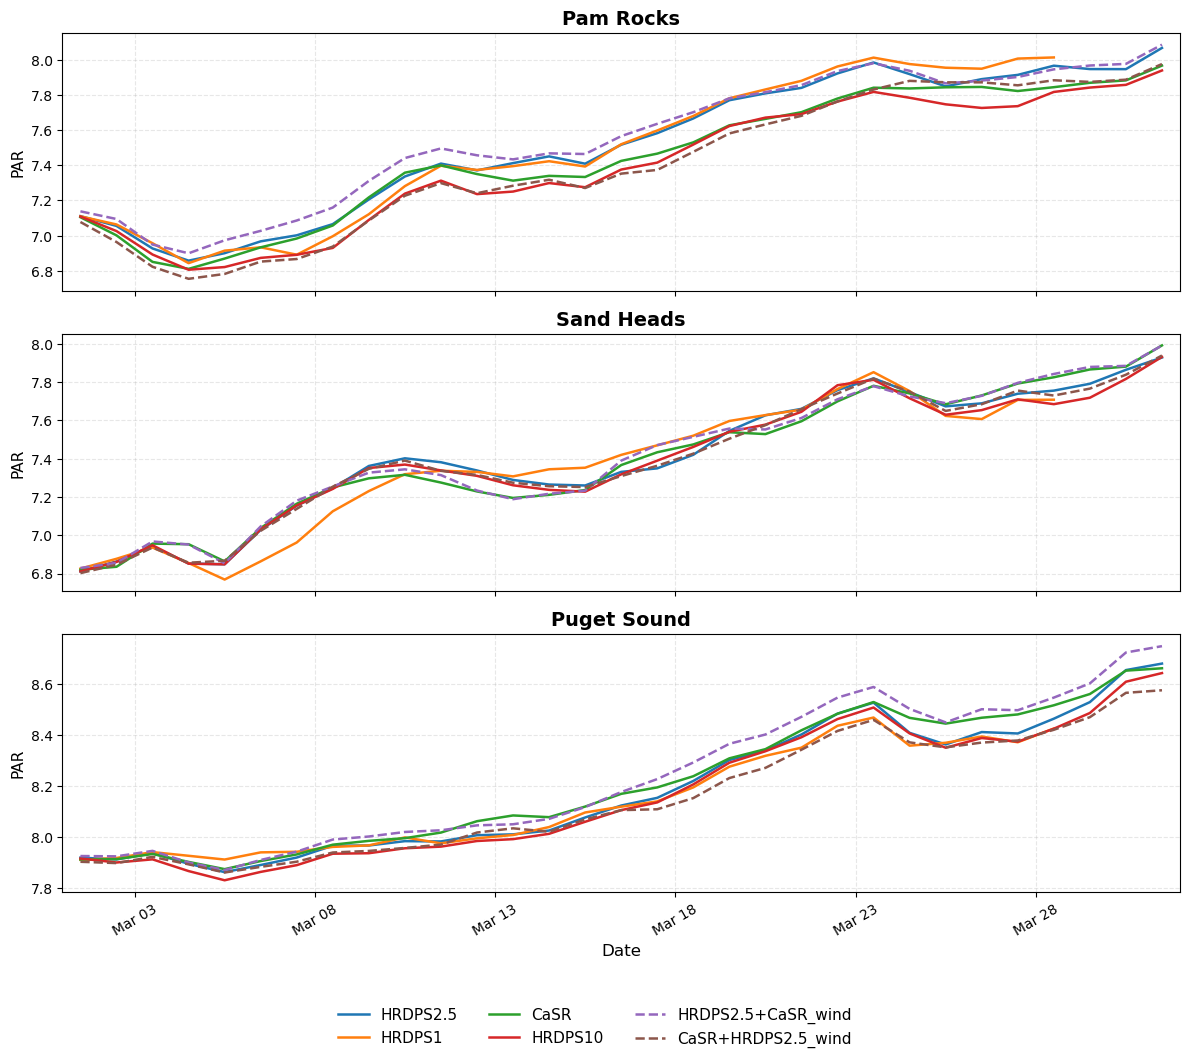

In [24]:
# visualize temperature

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# ============================================================
# Settings
# ============================================================

VAR_NAME = "votemper"

REGIONS_TO_PLOT = {
    "Pam Rocks": "pam_rocks",
    "Sand Heads": "sandheads",
    "Puget Sound": "puget_sound",
}

MONTH = "Mar"
N_LEVELS = 20  # Top 20 vertical layers

path_weights = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_sensitivity/Weights_Area/"
)

# Experiment colors
EXPERIMENT_COLORS = {
    "HRDPS2.5": "tab:blue",
    "HRDPS1": "tab:orange",
    "CaSR": "tab:green",
    "HRDPS10": "tab:red",
    "HRDPS2.5+CaSR_wind": "tab:purple",
    "CaSR+HRDPS2.5_wind": "tab:brown",
}


LINESTYLES = {
    "HRDPS2.5": "-",
    "HRDPS1": "-",
    "CaSR": "-",
    "HRDPS10": "-",
    "HRDPS2.5+CaSR_wind": "--",
    "CaSR+HRDPS2.5_wind": "--",
}

# Load Weights

region_weights = {}

for region_name, region_file in REGIONS_TO_PLOT.items():

    weight_file = path_weights / f"{region_file}_weights.nc"

    with xr.open_dataset(weight_file) as ds_w:

        weights = ds_w["weights"].isel(
            deptht=slice(0, N_LEVELS)
        ).load()

    # Renormalize weights for top 20 layers
    weights = weights / weights.sum(
        dim=("deptht", "y", "x")
    )

    region_weights[region_name] = weights

    print(
        f"{region_name:15s}: "
        f"Top {N_LEVELS} layers weights sum = "
        f"{weights.sum().item():.6f}"
    )


# Calculate means


# Structure:
# results[region][experiment] = DataArray(time_counter)

results = {
    region: {}
    for region in REGIONS_TO_PLOT
}

spatial_dims = ("deptht", "y", "x")

for exp_name, exp_paths in EXPERIMENTS_head.items():

    if MONTH not in exp_paths:
        continue

    file_path = (
        exp_paths[MONTH]
        + EXPERIMENTS_tail["Physical"]
    )

    if not Path(file_path).exists():
        print(f"File not found: {file_path}")
        continue

    print(f"\nProcessing experiment: {exp_name}")

    with xr.open_dataset(
        file_path,
        chunks={"time_counter": 1}
    ) as ds:

        if VAR_NAME not in ds:
            print(f"  Variable not found: {VAR_NAME}")
            continue

        # Select top 20 layers
        var = ds[VAR_NAME].isel(
            deptht=slice(0, N_LEVELS)
        )

        for region_name, weights in region_weights.items():

            # Volume-weighted mean
            # Renormalize for any missing values

            numerator = (var * weights).sum(
                dim=spatial_dims
            )

            denominator = weights.where(
                var.notnull()
            ).sum(dim=spatial_dims)

            regional_mean = numerator / denominator

            # Load only the reduced time series
            results[region_name][exp_name] = (
                regional_mean.load()
            )

        print(f"  Finished: {VAR_NAME}")


# Visualize Temperature

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 11),
    sharex=True
)

regions = list(REGIONS_TO_PLOT.keys())

for i, region_name in enumerate(regions):

    ax = axes[i]

    for exp_name, ts in results[region_name].items():

        ax.plot(
            ts["time_counter"].values,
            ts.values,
            label=exp_name,
            color=EXPERIMENT_COLORS.get(exp_name),
            linestyle=LINESTYLES.get(exp_name),
            linewidth=1.8,
        )

    ax.set_title(
        region_name,
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel(
        "PAR",
        fontsize=11
    )

    ax.grid(alpha=0.3, linestyle="--")

    ax.xaxis.set_major_locator(
        mdates.DayLocator(interval=5)
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%b %d")
    )

    ax.tick_params(axis="x", rotation=30)

    ax.set_xlim(
        np.datetime64("2023-03-01"),
        np.datetime64("2023-04-01")
    )

axes[-1].set_xlabel("Date", fontsize=12)


# layout


handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    fontsize=11
)

plt.tight_layout(rect=[0, 0.09, 1, 0.98])

plt.show()

## Scatter

### Diatom

In [1]:
# Example: "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/" + "SalishSea_1d_20230301_20230331_grid_T.nc"

EXPERIMENTS_head = {
    "HRDPS2.5": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS1": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps1/"
            "SalishSea_1d_20230301_20230328"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps1/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps1/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "CaSR": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_CaSR/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_CaSR/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS10": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps10/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps10/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps10/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS2.5+CaSR_wind": {
            "Mar": (
                "/ocean/jqiu/results/Sensivity/CaSR_wind_HRDPS_else/"
                "SalishSea_1d_20230301_20230331"
        ),
    },
    "CaSR+HRDPS2.5_wind": {
                "Mar": (
                    "/ocean/jqiu/results/Sensivity/HRDPS_wind_CaSR_else/"
                    "SalishSea_1d_20230301_20230331"
            ),
    },
}


EXPERIMENTS_tail = {
    'Physical': '_grid_T.nc',
    'Biological': '_biol_T.nc',
    'Velocity_u': '_grid_U.nc',
    'Velocity_v': '_grid_V.nc',
    'Chemical': '_chem_T.nc'
}

# List_month={'Mar','Jun','Sep','Dec'}
List_month={'Mar'}




DAILY DIATOMS MEAN BIAS
Bias = Experiment - HRDPS2.5
     Region Experiment    Bias  N_days
 Sand Heads     HRDPS1 +0.0193      28
 Sand Heads    HRDPS10 +0.0243      31
 Sand Heads       CaSR +0.2223      31
Puget Sound     HRDPS1 -0.0693      28
Puget Sound    HRDPS10 +0.0332      31
Puget Sound       CaSR +0.3429      31


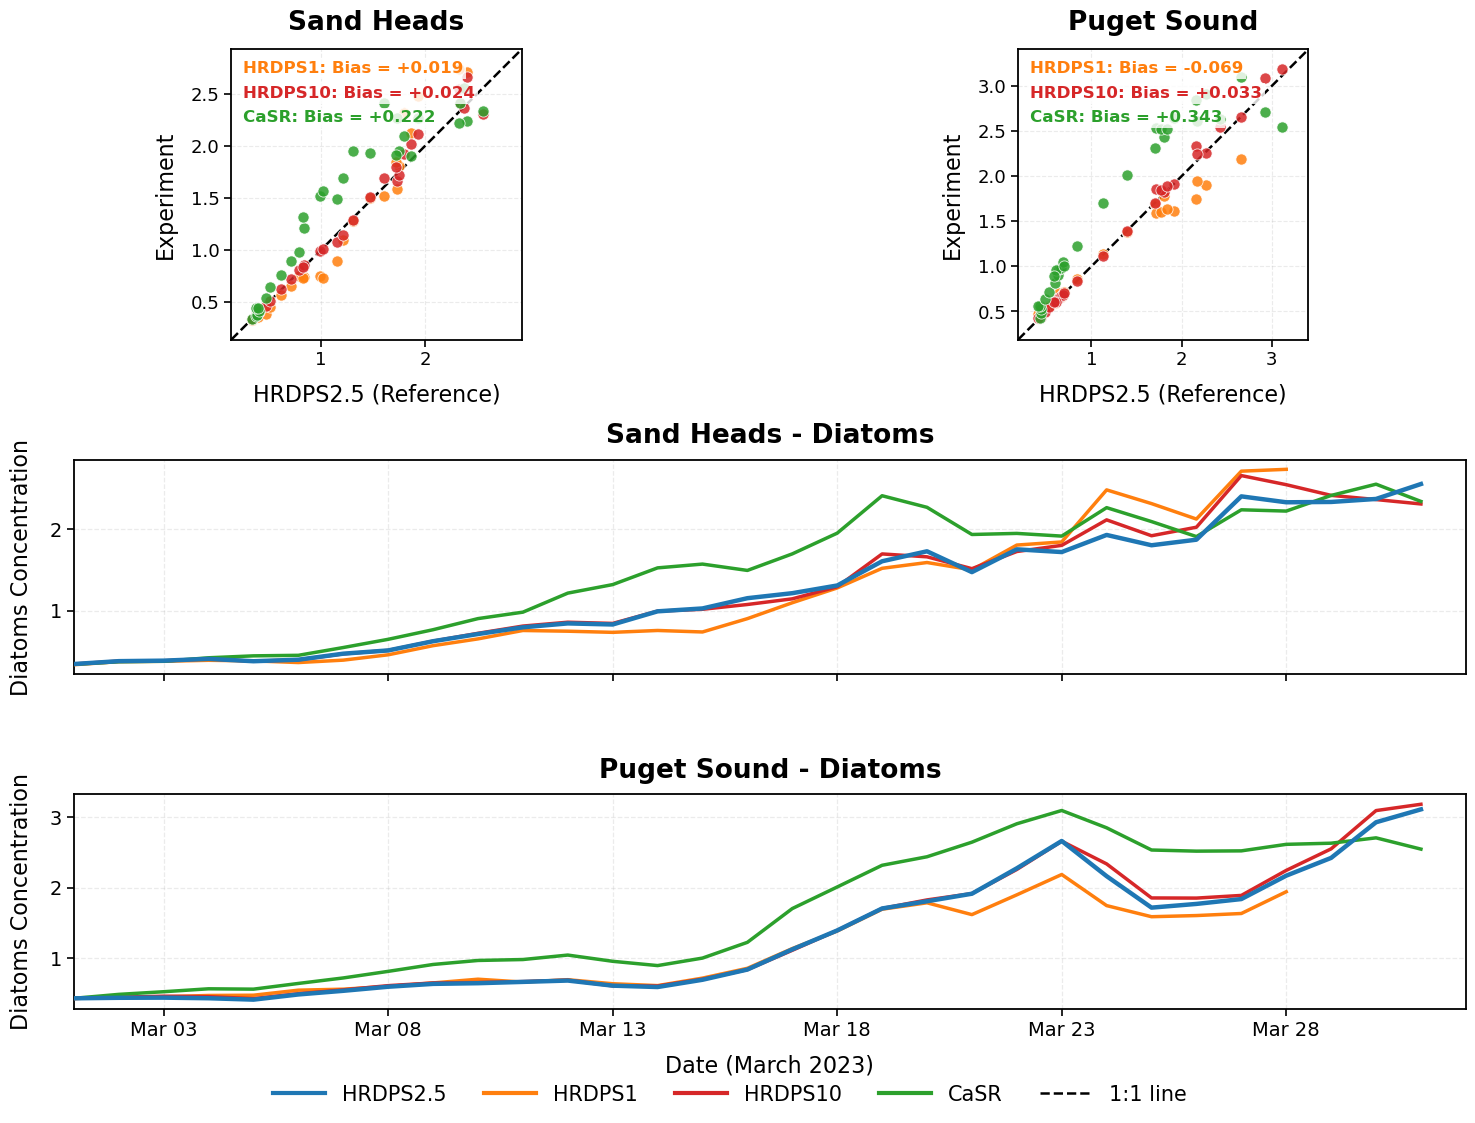

In [ ]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# ============================================================
# Settings
# ============================================================

BIO_VAR = "diatoms"

REGIONS_TO_PLOT = {
    "Sand Heads": "sandheads",
    "Puget Sound": "puget_sound",
}

MONTH = "Mar"
N_LEVELS = 20

REFERENCE = "HRDPS2.5"
EXPERIMENTS_TO_PLOT = ["HRDPS1", "HRDPS10", "CaSR"]

ALL_EXPERIMENTS = [REFERENCE] + EXPERIMENTS_TO_PLOT

EXPERIMENT_COLORS = {
    "HRDPS2.5": "tab:blue",
    "HRDPS1": "tab:orange",
    "HRDPS10": "tab:red",
    "CaSR": "tab:green",
}

path_weights = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_sensitivity/Weights_Area/"
)

spatial_dims = ("deptht", "y", "x")

# ============================================================
# 1. Load regional weights (Top 20 layers)
# ============================================================

region_weights = {}

for region_name, region_file in REGIONS_TO_PLOT.items():

    weight_file = path_weights / f"{region_file}_weights.nc"

    with xr.open_dataset(weight_file) as ds_w:

        weights = ds_w["weights"].isel(
            deptht=slice(0, N_LEVELS)
        ).load()

    # Normalize weights over top 20 layers
    weights = weights / weights.sum(dim=spatial_dims)

    region_weights[region_name] = weights

    print(
        f"{region_name:15s}: "
        f"weights sum = {weights.sum().item():.6f}"
    )


# ============================================================
# 2. Calculate regional mean Diatoms
# ============================================================

# results[region][experiment] = daily mean DataArray

results = {
    region: {}
    for region in REGIONS_TO_PLOT
}

for exp_name in ALL_EXPERIMENTS:

    if exp_name not in EXPERIMENTS_head:
        print(f"Experiment not found: {exp_name}")
        continue

    exp_paths = EXPERIMENTS_head[exp_name]

    if MONTH not in exp_paths:
        print(f"Month not found: {exp_name}, {MONTH}")
        continue

    file_path = (
        exp_paths[MONTH]
        + EXPERIMENTS_tail["Biological"]
    )

    if not Path(file_path).exists():
        print(f"File not found: {file_path}")
        continue

    print(f"\nProcessing: {exp_name}")

    with xr.open_dataset(
        file_path,
        chunks={"time_counter": 1}
    ) as ds:

        if BIO_VAR not in ds:
            print(f"Variable not found: {BIO_VAR}")
            continue

        var = ds[BIO_VAR].isel(
            deptht=slice(0, N_LEVELS)
        )

        for region_name, weights in region_weights.items():

            # Volume-weighted regional mean
            numerator = (var * weights).sum(
                dim=spatial_dims
            )

            denominator = weights.where(
                var.notnull()
            ).sum(dim=spatial_dims)

            regional_mean = numerator / denominator

            # Daily average: one value per day
            daily_mean = regional_mean.resample(
                time_counter="1D"
            ).mean()

            results[region_name][exp_name] = daily_mean.load()

            print(f"  Finished: {region_name}")


# ============================================================
# 3. Visualization: 3 rows x 2 columns
#
# Row 1: Scatter plots (Sand Heads | Puget Sound)
# Row 2: Sand Heads time series (full width)
# Row 3: Puget Sound time series (full width)
# ============================================================

fig = plt.figure(figsize=(15, 13))

gs = fig.add_gridspec(
    nrows=3,
    ncols=2,
    height_ratios=[1.2, 1, 1],
    hspace=0.38,
    wspace=0.28,
)

ax_scatter_SH = fig.add_subplot(gs[0, 0])
ax_scatter_PS = fig.add_subplot(gs[0, 1])

ax_ts_SH = fig.add_subplot(gs[1, :])
ax_ts_PS = fig.add_subplot(gs[2, :], sharex=ax_ts_SH)

scatter_axes = {
    "Sand Heads": ax_scatter_SH,
    "Puget Sound": ax_scatter_PS,
}

ts_axes = {
    "Sand Heads": ax_ts_SH,
    "Puget Sound": ax_ts_PS,
}


# ============================================================
# 4. First row: Daily scatter plots
# ============================================================

for region_name, ax in scatter_axes.items():

    region_data = results[region_name]

    if REFERENCE not in region_data:
        print(f"Missing reference: {region_name}")
        continue

    ref = region_data[REFERENCE]

    all_values = []

    for exp_name in EXPERIMENTS_TO_PLOT:

        if exp_name not in region_data:
            continue

        exp = region_data[exp_name]

        # Align daily time coordinates
        ref_aligned, exp_aligned = xr.align(
            ref, exp, join="inner"
        )

        x = ref_aligned.values
        y = exp_aligned.values

        # Remove NaNs
        valid = np.isfinite(x) & np.isfinite(y)

        x = x[valid]
        y = y[valid]

        if len(x) == 0:
            continue

        ax.scatter(
            x,
            y,
            s=35,
            alpha=0.8,
            color=EXPERIMENT_COLORS[exp_name],
            label=exp_name,
            edgecolors="white",
            linewidths=0.4,
        )

        all_values.extend(x)
        all_values.extend(y)

    # 1:1 reference line
    if len(all_values) > 0:

        vmin = np.min(all_values)
        vmax = np.max(all_values)

        margin = (vmax - vmin) * 0.05

        if margin == 0:
            margin = max(abs(vmax) * 0.05, 0.01)

        lims = [
            vmin - margin,
            vmax + margin,
        ]

        ax.plot(
            lims,
            lims,
            color="black",
            linestyle="--",
            linewidth=1.2,
            label="1:1 line",
        )

        ax.set_xlim(lims)
        ax.set_ylim(lims)

    ax.set_aspect("equal", adjustable="box")

    ax.set_title(
        f"{region_name} - Daily Diatoms",
        fontsize=13,
        fontweight="bold",
    )

    ax.set_xlabel(
        "HRDPS2.5 (Reference)",
        fontsize=11,
    )

    ax.set_ylabel(
        "Experiments",
        fontsize=11,
    )

    ax.grid(alpha=0.3, linestyle="--")


# ============================================================
# 5. Second and third rows: Daily time series
# ============================================================

for region_name, ax in ts_axes.items():

    region_data = results[region_name]

    for exp_name in ALL_EXPERIMENTS:

        if exp_name not in region_data:
            continue

        ts = region_data[exp_name]

        # Highlight reference
        if exp_name == REFERENCE:
            linewidth = 2.5
            linestyle = "-"
            zorder = 5
        else:
            linewidth = 1.8
            linestyle = "-"
            zorder = 3

        ax.plot(
            ts["time_counter"].values,
            ts.values,
            label=exp_name,
            color=EXPERIMENT_COLORS[exp_name],
            linewidth=linewidth,
            linestyle=linestyle,
            zorder=zorder,
        )

    ax.set_title(
        f"{region_name} - Diatoms Time Series",
        fontsize=13,
        fontweight="bold",
    )

    ax.set_ylabel(
        "Diatoms Concentration",
        fontsize=11,
    )

    ax.grid(alpha=0.3, linestyle="--")

    ax.xaxis.set_major_locator(
        mdates.DayLocator(interval=5)
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%b %d")
    )

    ax.set_xlim(
        np.datetime64("2023-03-01"),
        np.datetime64("2023-04-01"),
    )

    ax.tick_params(axis="x", rotation=30)


ax_ts_PS.set_xlabel("Date", fontsize=11)


# ============================================================
# 6. Shared legend and layout
# ============================================================

# Use time-series handles for a clean shared legend
handles, labels = ax_ts_SH.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.015),
    ncol=4,
    frameon=False,
    fontsize=11,
)

fig.suptitle(
    "Diatoms Comparison: Atmospheric Forcing Experiments",
    fontsize=16,
    fontweight="bold",
    y=0.98,
)

fig.subplots_adjust(
    top=0.93,
    bottom=0.09,
)

plt.show()


DAILY DIATOMS BIAS AND SIGNIFICANCE
Bias = Experiment - HRDPS2.5
     Region Experiment    Bias  t_stat  p_value Significance  N_days
 Sand Heads     HRDPS1  0.0193  0.4879   0.6295           ns      28
 Sand Heads    HRDPS10  0.0243  1.4397   0.1603           ns      31
 Sand Heads       CaSR  0.2223  4.9607   0.0000          ***      31
Puget Sound     HRDPS1 -0.0693 -2.3616   0.0257            *      28
Puget Sound    HRDPS10  0.0332  3.5220   0.0014           **      31
Puget Sound       CaSR  0.3429  6.2946   0.0000          ***      31


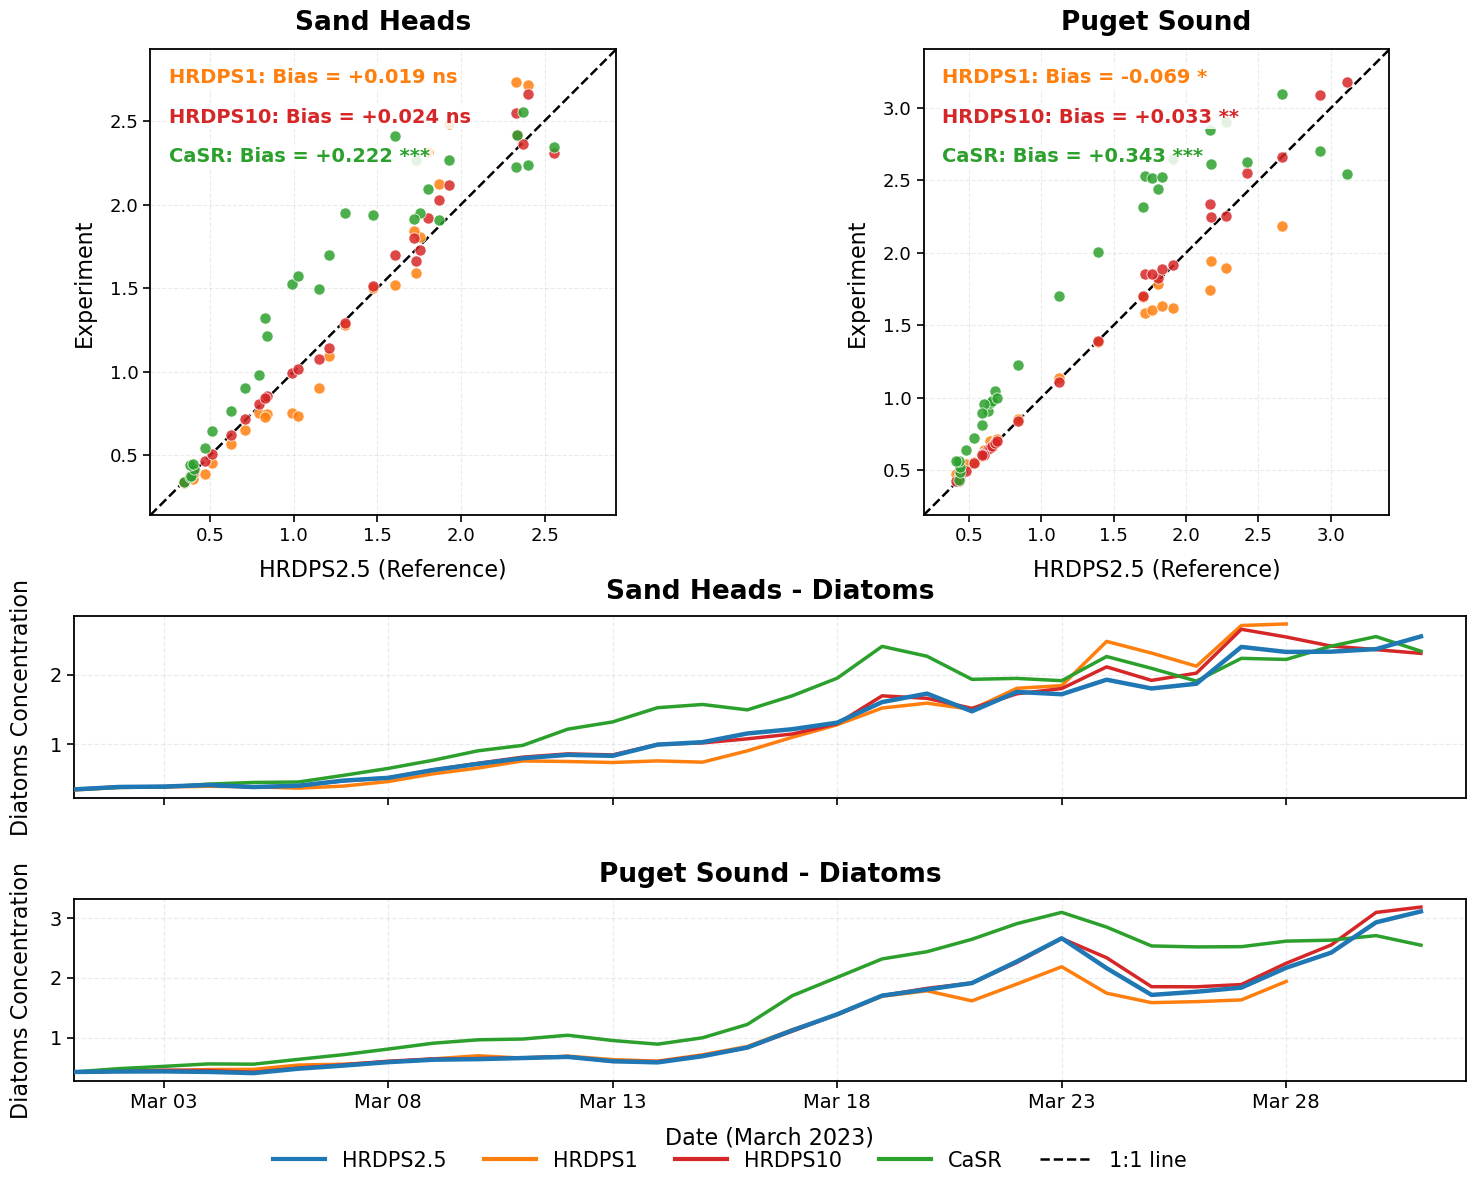

In [ ]:


# layout

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 15,
    "axes.titlesize": 20,
    "axes.titleweight": "bold",
    "axes.labelsize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 15,
    "axes.linewidth": 1.3,
    "savefig.dpi": 300,
})

fig = plt.figure(
    figsize=(16, 12),
    facecolor="white"
)

gs = fig.add_gridspec(
    nrows=4,
    ncols=2,
    height_ratios=[1, 1, 1, 1],
    hspace=0.55,
    wspace=0.25,
    left=0.09,
    right=0.96,
    top=0.96,
    bottom=0.10,
)

# First two rows: scatter plots
ax_scatter_SH = fig.add_subplot(gs[0:2, 0])
ax_scatter_PS = fig.add_subplot(gs[0:2, 1])

# Third row: Sand Heads time series
ax_ts_SH = fig.add_subplot(gs[2, :])

# Fourth row: Puget Sound time series
ax_ts_PS = fig.add_subplot(
    gs[3, :],
    sharex=ax_ts_SH
)

scatter_axes = {
    "Sand Heads": ax_scatter_SH,
    "Puget Sound": ax_scatter_PS,
}

ts_axes = {
    "Sand Heads": ax_ts_SH,
    "Puget Sound": ax_ts_PS,
}


# Mean Bias


# Bias = mean(Experiment - HRDPS2.5)
# Based on matched daily values

# ============================================================
# 4. Calculate Mean Bias and paired t-test
# ============================================================

from scipy.stats import ttest_rel
import pandas as pd

bias_results = []

for region_name in REGIONS_TO_PLOT:

    region_data = results[region_name]

    if REFERENCE not in region_data:
        continue

    ref = region_data[REFERENCE]

    for exp_name in EXPERIMENTS_TO_PLOT:

        if exp_name not in region_data:
            continue

        exp = region_data[exp_name]

        # Align daily data
        ref_aligned, exp_aligned = xr.align(
            ref, exp, join="inner"
        )

        x = np.asarray(ref_aligned.values).ravel()
        y = np.asarray(exp_aligned.values).ravel()

        valid = np.isfinite(x) & np.isfinite(y)

        x = x[valid]
        y = y[valid]

        if len(x) < 2:
            continue

        # Mean Bias
        bias = np.mean(y - x)

        # Paired t-test
        t_stat, p_value = ttest_rel(y, x)

        # Significance label
        if p_value < 0.001:
            significance = "***"
        elif p_value < 0.01:
            significance = "**"
        elif p_value < 0.05:
            significance = "*"
        else:
            significance = "ns"

        bias_results.append({
            "Region": region_name,
            "Experiment": exp_name,
            "Bias": bias,
            "t_stat": t_stat,
            "p_value": p_value,
            "Significance": significance,
            "N_days": len(x),
        })

bias_df = pd.DataFrame(bias_results)

print("\nDAILY DIATOMS BIAS AND SIGNIFICANCE")
print("Bias = Experiment - HRDPS2.5")

print(
    bias_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)





# scatter plots + Bias


for region_name, ax in scatter_axes.items():

    region_data = results[region_name]

    if REFERENCE not in region_data:
        continue

    ref = region_data[REFERENCE]

    all_values = []

    for exp_name in EXPERIMENTS_TO_PLOT:

        if exp_name not in region_data:
            continue

        exp = region_data[exp_name]

        ref_aligned, exp_aligned = xr.align(
            ref, exp, join="inner"
        )

        x = np.asarray(ref_aligned.values).ravel()
        y = np.asarray(exp_aligned.values).ravel()

        valid = np.isfinite(x) & np.isfinite(y)

        x = x[valid]
        y = y[valid]

        if len(x) == 0:
            continue

        ax.scatter(
            x,
            y,
            s=65,
            alpha=0.85,
            color=EXPERIMENT_COLORS[exp_name],
            edgecolors="white",
            linewidths=0.6,
            zorder=3,
        )

        all_values.extend(x)
        all_values.extend(y)

    # 1:1 line
    if len(all_values) > 0:

        vmin = np.min(all_values)
        vmax = np.max(all_values)

        margin = 0.08 * (vmax - vmin)

        if margin == 0:
            margin = max(abs(vmax) * 0.05, 0.01)

        lims = [
            vmin - margin,
            vmax + margin
        ]

        ax.plot(
            lims,
            lims,
            color="black",
            linestyle="--",
            linewidth=1.8,
            zorder=2,
        )

        ax.set_xlim(lims)
        ax.set_ylim(lims)

    ax.set_aspect("equal", adjustable="box")

    ax.set_title(
        f"{region_name}",
        fontsize=19,
        fontweight="bold",
        pad=14,
    )

    ax.set_xlabel(
        "HRDPS2.5 (Reference)",
        fontsize=16,
        labelpad=10,
    )

    ax.set_ylabel(
        "Experiment",
        fontsize=16,
        labelpad=10,
    )

    ax.tick_params(
        axis="both",
        labelsize=13,
        width=1.2,
        length=5,
    )

    ax.grid(
        alpha=0.25,
        linestyle="--",
        linewidth=0.8,
    )

    # ----------------------------------------
    # Display Bias for each experiment
    # ----------------------------------------

    region_bias = bias_df[
        bias_df["Region"] == region_name
    ]

    # Bias text, top-left inside each plot
    for idx, exp_name in enumerate(EXPERIMENTS_TO_PLOT):

        row = region_bias[
            region_bias["Experiment"] == exp_name
        ]

        if row.empty:
            continue

        bias = row["Bias"].iloc[0]
        sig = row["Significance"].iloc[0]

        ax.text(
            0.04,
            0.96 - idx * 0.085,
            f"{exp_name}: Bias = {bias:+.3f} {sig}",
            transform=ax.transAxes,
            fontsize=14,
            fontweight="semibold",
            color=EXPERIMENT_COLORS[exp_name],
            verticalalignment="top",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.85,
                pad=2,
            ),
            zorder=10,
        )


# ============================================================
# 6. Second and third rows: Time series
# ============================================================

for region_name, ax in ts_axes.items():

    region_data = results[region_name]

    for exp_name in ALL_EXPERIMENTS:

        if exp_name not in region_data:
            continue

        ts = region_data[exp_name]

        if exp_name == REFERENCE:
            linewidth = 3.2
            zorder = 5
        else:
            linewidth = 2.5
            zorder = 3

        ax.plot(
            ts["time_counter"].values,
            ts.values,
            label=exp_name,
            color=EXPERIMENT_COLORS[exp_name],
            linewidth=linewidth,
            zorder=zorder,
        )

    ax.set_title(
        f"{region_name} - Diatoms",
        fontsize=19,
        fontweight="bold",
        pad=12,
    )

    ax.set_ylabel(
        "Diatoms Concentration",
        fontsize=16,
        labelpad=12,
    )

    ax.grid(
        alpha=0.25,
        linestyle="--",
        linewidth=0.9,
    )

    ax.tick_params(
        axis="both",
        labelsize=14,
        width=1.2,
        length=5,
    )

    ax.xaxis.set_major_locator(
        mdates.DayLocator(interval=5)
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%b %d")
    )

    ax.set_xlim(
        np.datetime64("2023-03-01"),
        np.datetime64("2023-04-01"),
    )

    ax.tick_params(
        axis="x",
        rotation=0,
    )

# Hide upper time-series x tick labels
ax_ts_SH.tick_params(
    axis="x",
    labelbottom=False,
)

ax_ts_PS.set_xlabel(
    "Date (March 2023)",
    fontsize=16,
    labelpad=10,
)


# ============================================================
# 7. Shared legend
# ============================================================

legend_handles = []

for exp_name in ALL_EXPERIMENTS:

    legend_handles.append(
        Line2D(
            [0], [0],
            color=EXPERIMENT_COLORS[exp_name],
            linewidth=3,
            label=exp_name,
        )
    )

# Add 1:1 line to legend
legend_handles.append(
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        linewidth=1.8,
        label="1:1 line",
    )
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=5,
    frameon=False,
    fontsize=15,
    handlelength=2.5,
    columnspacing=1.8,
)



plt.show()


### Wind Stress


Reading: /ocean/jqiu/results/Flux/flux_00mar23_CaSR/SalishSea_1d_20230301_20230331_sbfx_T.nc
  Finished: Pam Rocks
  Finished: Sand Heads
  Finished: Puget Sound

Reading: /ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/SalishSea_1d_20230301_20230331_sbfx_T.nc
  Finished: Pam Rocks
  Finished: Sand Heads
  Finished: Puget Sound

Reading: /ocean/jqiu/results/Flux/flux_00mar23_hrdps1/SalishSea_1d_20230301_20230328_sbfx_T.nc
  Finished: Pam Rocks
  Finished: Sand Heads
  Finished: Puget Sound

Reading: /ocean/jqiu/results/Flux/flux_00mar23_hrdps10/SalishSea_1d_20230301_20230331_sbfx_T.nc
  Finished: Pam Rocks
  Finished: Sand Heads
  Finished: Puget Sound

WIND STRESS BIAS AND SIGNIFICANCE
Bias = Experiment - HRDPS2.5
Units: N m^-2
     Region Experiment     Bias   t_stat  p_value Significance  N_pairs
 Sand Heads       CaSR  0.00380  1.79470  0.08278           ns       31
 Sand Heads     HRDPS1  0.00407  1.96420  0.05988           ns       28
 Sand Heads    HRDPS10 -0.00119 -8.50881  0.0

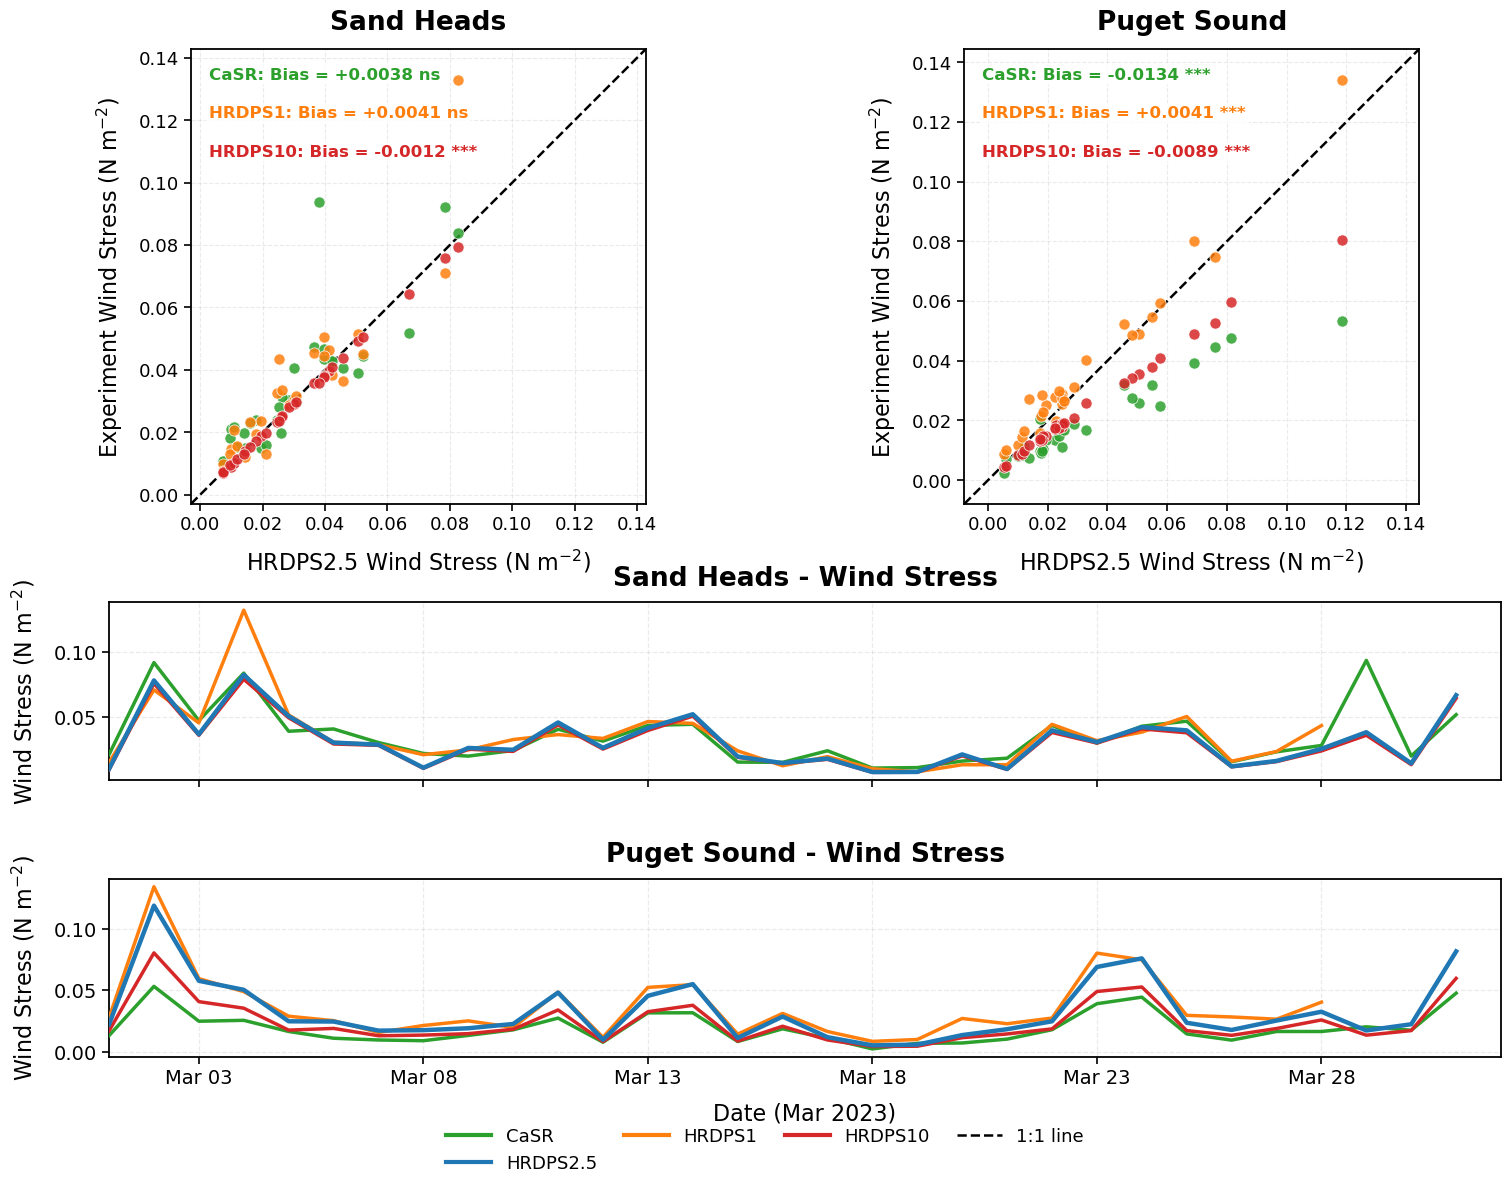

In [ ]:

import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from pathlib import Path
from scipy.stats import ttest_rel
from matplotlib.lines import Line2D


# Settings

MASK_FILE = "/ocean/jqiu/Grid/mesh_mask202108.nc"
AREA_FILE = "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/SalishSea_1d_20230301_20230331_biol_T.nc"


ds_grid=xr.open_dataset(MASK_FILE)
tmask=ds_grid['tmask'] # String flag_meanings "land, water"; String flag_values "0, 1", (t, z, y, x)
e3t=ds_grid['e3t_1d'] # "Grid Spacing on T-grid in w Direction", (t, z)
depth=ds_grid['gdept_1d'] # "Depth of T-grid Points", String units "m", (t, z)

ds_area=xr.open_dataset(AREA_FILE)
area=ds_area['area'] # 

MONTH = "Mar"

REFERENCE = "HRDPS2.5"

MODELS = [
    "CaSR",
    "HRDPS2.5",
    "HRDPS1",
    "HRDPS10",
]

EXPERIMENTS_TO_PLOT = [
    model for model in MODELS
    if model != REFERENCE
]

VARIABLE = "wind stress"
FILE_SUFFIX = "_sbfx_T.nc"

REGIONS_TO_PLOT = {
    "Pam Rocks": (490, 510, 330, 350),
    "Sand Heads": (420, 440, 280, 300),
    "Puget Sound": (75, 125, 225, 280),
}

# Two regions for combined figure
PLOT_REGIONS = [
    "Sand Heads",
    "Puget Sound",
]

EXPERIMENT_COLORS = {
    "HRDPS2.5": "tab:blue",
    "HRDPS1": "tab:orange",
    "CaSR": "tab:green",
    "HRDPS10": "tab:red",
    "HRDPS2.5+CaSR_wind": "tab:purple",
    "CaSR+HRDPS2.5_wind": "tab:brown",
}

LINESTYLES = {
    "HRDPS2.5": "-",
    "HRDPS1": "-",
    "CaSR": "-",
    "HRDPS10": "-",
    "HRDPS2.5+CaSR_wind": "--",
    "CaSR+HRDPS2.5_wind": "--",
}


# Area weights


area_2d = ds_area["area"].squeeze(drop=True)

surface_mask = ds_grid["tmask"].isel(
    t=0,
    z=0,
    drop=True
)

area_weights = area_2d.where(surface_mask == 1)


# calculate wind stress


# results[region][model] = xarray DataArray
# Keep time coordinates for alignment

results = {
    region: {}
    for region in REGIONS_TO_PLOT
}

for model in MODELS:

    if MONTH not in EXPERIMENTS_head.get(model, {}):
        print(f"WARNING: {MONTH} not available for {model}")
        continue

    file_path = Path(
        EXPERIMENTS_head[model][MONTH] + FILE_SUFFIX
    )

    print(f"\nReading: {file_path}")

    if not file_path.exists():
        print(f"WARNING: file not found: {file_path}")
        continue

    with xr.open_dataset(file_path) as ds:

        if VARIABLE not in ds:
            print(f"WARNING: {VARIABLE} not found")
            continue

        for region_name, (j0, j1, i0, i1) in REGIONS_TO_PLOT.items():

            data = ds[VARIABLE].isel(
                y=slice(j0, j1),
                x=slice(i0, i1)
            )

            weights = area_weights.isel(
                y=slice(j0, j1),
                x=slice(i0, i1)
            )

            data = data.where(np.isfinite(data))

            numerator = (data * weights).sum(
                dim=("y", "x"),
                skipna=True
            )

            denominator = weights.where(
                data.notnull()
            ).sum(
                dim=("y", "x"),
                skipna=True
            )

            mean_data = numerator / denominator

            mean_data = mean_data.resample(
                time_counter="1D"
            ).mean()
            results[region_name][model] = mean_data.load()

            print(f"  Finished: {region_name}")


# mean bias and paired t-test


# Bias = Experiment - HRDPS2.5

bias_results = []

for region_name in PLOT_REGIONS:

    region_data = results[region_name]

    if REFERENCE not in region_data:
        continue

    ref = region_data[REFERENCE]

    for exp_name in EXPERIMENTS_TO_PLOT:

        if exp_name not in region_data:
            continue

        exp = region_data[exp_name]

        # Align matching time coordinates
        ref_aligned, exp_aligned = xr.align(
            ref,
            exp,
            join="inner"
        )

        x = np.asarray(ref_aligned.values).ravel()
        y = np.asarray(exp_aligned.values).ravel()

        valid = np.isfinite(x) & np.isfinite(y)

        x = x[valid]
        y = y[valid]

        if len(x) < 2:
            continue

        bias = np.mean(y - x)

        t_stat, p_value = ttest_rel(y, x)

        if p_value < 0.001:
            significance = "***"
        elif p_value < 0.01:
            significance = "**"
        elif p_value < 0.05:
            significance = "*"
        else:
            significance = "ns"

        bias_results.append({
            "Region": region_name,
            "Experiment": exp_name,
            "Bias": bias,
            "t_stat": t_stat,
            "p_value": p_value,
            "Significance": significance,
            "N_pairs": len(x),
        })


bias_df = pd.DataFrame(bias_results)

print("\nWIND STRESS BIAS AND SIGNIFICANCE")
print("Bias = Experiment - HRDPS2.5")
print("Units: N m^-2")

print(
    bias_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.5f}"
    )
)




# Figure 

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 15,
    "axes.titlesize": 20,
    "axes.titleweight": "bold",
    "axes.labelsize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 15,
    "axes.linewidth": 1.3,
    "savefig.dpi": 300,
})

fig = plt.figure(
    figsize=(16, 12),
    facecolor="white"
)

gs = fig.add_gridspec(
    nrows=4,
    ncols=2,
    height_ratios=[1, 1, 1, 1],
    hspace=0.55,
    wspace=0.25,
    left=0.09,
    right=0.96,
    top=0.96,
    bottom=0.12,
)

# Upper two rows: scatter plots
ax_scatter_SH = fig.add_subplot(gs[0:2, 0])
ax_scatter_PS = fig.add_subplot(gs[0:2, 1])

# Third row: Sand Heads time series
ax_ts_SH = fig.add_subplot(gs[2, :])

# Fourth row: Puget Sound time series
ax_ts_PS = fig.add_subplot(
    gs[3, :],
    sharex=ax_ts_SH
)

scatter_axes = {
    "Sand Heads": ax_scatter_SH,
    "Puget Sound": ax_scatter_PS,
}

ts_axes = {
    "Sand Heads": ax_ts_SH,
    "Puget Sound": ax_ts_PS,
}


# Scatter plots

for region_name, ax in scatter_axes.items():

    region_data = results[region_name]

    if REFERENCE not in region_data:
        continue

    ref = region_data[REFERENCE]

    all_values = []

    for exp_name in EXPERIMENTS_TO_PLOT:

        if exp_name not in region_data:
            continue

        exp = region_data[exp_name]

        ref_aligned, exp_aligned = xr.align(
            ref,
            exp,
            join="inner"
        )

        x = np.asarray(ref_aligned.values).ravel()
        y = np.asarray(exp_aligned.values).ravel()

        valid = np.isfinite(x) & np.isfinite(y)

        x = x[valid]
        y = y[valid]

        if len(x) == 0:
            continue

        ax.scatter(
            x,
            y,
            s=65,
            alpha=0.85,
            color=EXPERIMENT_COLORS[exp_name],
            edgecolors="white",
            linewidths=0.6,
            zorder=3,
        )

        all_values.extend(x)
        all_values.extend(y)

    # 1:1 reference line
    if len(all_values) > 0:

        vmin = np.min(all_values)
        vmax = np.max(all_values)

        margin = 0.08 * (vmax - vmin)

        if margin == 0:
            margin = max(abs(vmax) * 0.05, 0.01)

        lims = [
            vmin - margin,
            vmax + margin
        ]

        ax.plot(
            lims,
            lims,
            color="black",
            linestyle="--",
            linewidth=1.8,
            zorder=2,
        )

        ax.set_xlim(lims)
        ax.set_ylim(lims)

    ax.set_aspect("equal", adjustable="box")

    ax.set_title(
        region_name,
        fontsize=19,
        fontweight="bold",
        pad=14,
    )

    ax.set_xlabel(
        "HRDPS2.5 Wind Stress (N m$^{-2}$)",
        fontsize=16,
        labelpad=10,
    )

    ax.set_ylabel(
        "Experiment Wind Stress (N m$^{-2}$)",
        fontsize=16,
        labelpad=10,
    )

    ax.tick_params(
        axis="both",
        labelsize=13,
        width=1.2,
        length=5,
    )

    ax.grid(
        alpha=0.25,
        linestyle="--",
        linewidth=0.8,
    )

    # ----------------------------------------
    # Bias annotation
    # ----------------------------------------

    region_bias = bias_df[
        bias_df["Region"] == region_name
    ]

    for idx, exp_name in enumerate(EXPERIMENTS_TO_PLOT):

        row = region_bias[
            region_bias["Experiment"] == exp_name
        ]

        if row.empty:
            continue

        bias = row["Bias"].iloc[0]
        sig = row["Significance"].iloc[0]

        ax.text(
            0.04,
            0.96 - idx * 0.085,
            f"{exp_name}: Bias = {bias:+.4f} {sig}",
            transform=ax.transAxes,
            fontsize=12,
            fontweight="semibold",
            color=EXPERIMENT_COLORS[exp_name],
            verticalalignment="top",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.85,
                pad=2,
            ),
            zorder=10,
        )


# time series

for region_name, ax in ts_axes.items():

    region_data = results[region_name]

    for exp_name in MODELS:

        if exp_name not in region_data:
            continue

        ts = region_data[exp_name]

        if exp_name == REFERENCE:
            linewidth = 3.2
            zorder = 5
        else:
            linewidth = 2.5
            zorder = 3

        # Use time coordinates from DataArray
        if "time_counter" in ts.coords:
            time_values = ts["time_counter"].values
        else:
            time_values = np.arange(ts.size)

        ax.plot(
            time_values,
            ts.values,
            label=exp_name,
            color=EXPERIMENT_COLORS[exp_name],
            linestyle=LINESTYLES[exp_name],
            linewidth=linewidth,
            zorder=zorder,
        )

    ax.set_title(
        f"{region_name} - Wind Stress",
        fontsize=19,
        fontweight="bold",
        pad=12,
    )

    ax.set_ylabel(
        "Wind Stress (N m$^{-2}$)",
        fontsize=16,
        labelpad=12,
    )

    ax.grid(
        alpha=0.25,
        linestyle="--",
        linewidth=0.9,
    )

    ax.tick_params(
        axis="both",
        labelsize=14,
        width=1.2,
        length=5,
    )




if (
    "HRDPS2.5" in results["Sand Heads"]
    and "time_counter"
    in results["Sand Heads"]["HRDPS2.5"].coords
):

    for ax in ts_axes.values():

        ax.xaxis.set_major_locator(
            mdates.DayLocator(interval=5)
        )

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%b %d")
        )

    month_number = {
        "Mar": 3,
        "Jun": 6,
        "Sep": 9,
        "Dec": 12,
    }[MONTH]

    start_date = pd.Timestamp(
        year=2023,
        month=month_number,
        day=1
    )

    end_date = start_date + pd.DateOffset(months=1)

    ax_ts_SH.set_xlim(
        start_date,
        end_date
    )

    ax_ts_PS.set_xlim(
        start_date,
        end_date
    )

    ax_ts_PS.set_xlabel(
        f"Date ({MONTH} 2023)",
        fontsize=16,
        labelpad=10,
    )

else:

    ax_ts_PS.set_xlabel(
        "Time index",
        fontsize=16,
        labelpad=10,
    )

ax_ts_SH.tick_params(
    axis="x",
    labelbottom=False,
)


# legend


legend_handles = []

for exp_name in MODELS:

    legend_handles.append(
        Line2D(
            [0], [0],
            color=EXPERIMENT_COLORS[exp_name],
            linestyle=LINESTYLES[exp_name],
            linewidth=3,
            label=exp_name,
        )
    )

legend_handles.append(
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        linewidth=1.8,
        label="1:1 line",
    )
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=5,
    frameon=False,
    fontsize=13,
    handlelength=2.5,
    columnspacing=1.5,
)



plt.show()
